<a href="https://colab.research.google.com/github/Aneena1234/Portfolio/blob/main/scam_image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("GPU not enabled. Check Runtime settings.")


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [ ]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module"
)

RAW_DIR = PROJECT_DIR / "raw"
SPLIT_DIR = PROJECT_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

for name in CLASSES:
    (RAW_DIR / name).mkdir(parents=True, exist_ok=True)

for split in ["train", "validation", "test"]:
    for name in CLASSES:
        (SPLIT_DIR / split / name).mkdir(
            parents=True, exist_ok=True
        )

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Classes:", len(CLASSES))
print("Target images:", len(CLASSES) * 1250)
print("Folder setup complete.")


Project: /content/drive/MyDrive/Scamundo_Image_Module
Classes: 8
Target images: 10000
Folder setup complete.


In [ ]:

%pip install -q -U datasets huggingface_hub pillow pandas


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 124.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 105.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 19.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0

In [ ]:

%pip install -q pandas==2.2.3 "huggingface_hub>=0.34.0,<1.0" "pillow>=10,<13"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 116.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 111.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.20.1 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0

In [ ]:

import torch
import pandas as pd
import PIL
import datasets
import huggingface_hub

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Pandas:", pd.__version__)
print("Pillow:", PIL.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


ImportError: cannot import name 'BucketNotFoundError' from 'huggingface_hub.errors' (/usr/local/lib/python3.13/dist-packages/huggingface_hub/errors.py)

In [ ]:

%pip install -q "huggingface_hub>=1.32,<2.0"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 20.6 MB/s eta 0:00:00


In [ ]:

import torch
import pandas as pd
import PIL
import datasets
import huggingface_hub
import transformers

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Pandas:", pd.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Transformers:", transformers.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nEnvironment verification successful!")


PyTorch: 2.11.0+cu130
GPU available: True
Pandas: 2.2.3
Datasets: 5.1.0
Hugging Face Hub: 1.33.0
Transformers: 5.20.1
GPU: Tesla T4

Environment verification successful!


In [ ]:

from huggingface_hub import HfApi

DATASET_ID = "shresthsamyak/phishing-website-screenshots"

api = HfApi()

files = list(
    api.list_repo_files(
        repo_id=DATASET_ID,
        repo_type="dataset"
    )
)

print("Total repository files:", len(files))
print("\nFirst 50 files:")

for file in files[:50]:
    print(file)


Total repository files: 8373

First 50 files:
.gitattributes
README.md
legitimate/111_wales_nhs_uk/homepage.png
legitimate/1177/homepage.png
legitimate/1199seiu_funds/checkout.png
legitimate/1199seiu_funds/dashboard.png
legitimate/1199seiu_funds/homepage.png
legitimate/1199seiu_funds/signup.png
legitimate/15min/homepage.png
legitimate/1cmerwzv/homepage.png
legitimate/1xbet/homepage.png
legitimate/2006_07/homepage.png
legitimate/21/homepage.png
legitimate/23andme/homepage.png
legitimate/3h_biomedical_ab/checkout.png
legitimate/3h_biomedical_ab/homepage.png
legitimate/3h_biomedical_ab/login.png
legitimate/404/homepage.png
legitimate/404/signup.png
legitimate/404_error/homepage.png
legitimate/404_error/payment.png
legitimate/404_error/signup.png
legitimate/5_8/homepage.png
legitimate/8_rivers/homepage.png
legitimate/9th_bgm/homepage.png
legitimate/a_digital_world_accessible_to_all/homepage.png
legitimate/a_digital_world_accessible_to_all/login.png
legitimate/a_digital_world_accessible_to_

In [ ]:

phishing_files = [
    f for f in files if f.startswith("phishing/")
    and f.lower().endswith(".png")
]

legitimate_files = [
    f for f in files if f.startswith("legitimate/")
    and f.lower().endswith(".png")
]

print("Phishing screenshots:", len(phishing_files))
print("Legitimate screenshots:", len(legitimate_files))
print("Total PNG screenshots:",
      len(phishing_files) + len(legitimate_files))


Phishing screenshots: 446
Legitimate screenshots: 7924
Total PNG screenshots: 8370


In [ ]:

from pathlib import Path
from huggingface_hub import hf_hub_download
from PIL import Image
import shutil

# Download to a temporary local cache first.
# Copy verified images into Google Drive.
CACHE = Path("/content/scamundo_download_cache")
CACHE.mkdir(parents=True, exist_ok=True)

def download_samples(repo_files, label, limit=50):
    destination = RAW_DIR / label
    destination.mkdir(parents=True, exist_ok=True)

    saved = 0

    for repo_path in repo_files[:limit]:
        try:
            local_path = hf_hub_download(
                repo_id=DATASET_ID,
                repo_type="dataset",
                filename=repo_path,
                cache_dir=str(CACHE)
            )

            # Verify the file is a readable image
            with Image.open(local_path) as im:
                im.verify()

            # Preserve unique filenames
            output_name = (
                repo_path.replace("/", "__")
            )
            output_path = destination / output_name

            if not output_path.exists():
                shutil.copy2(local_path, output_path)

            saved += 1

        except Exception as e:
            print("Skipped:", repo_path, "|", str(e)[:150])

    print(label, "images saved:", saved)

download_samples(
    phishing_files,
    "phishing_websites",
    limit=50
)

download_samples(
    legitimate_files,
    "legitimate_images",
    limit=50
)


NameError: name 'RAW_DIR' is not defined

In [ ]:

from pathlib import Path

# Google Drive must already be mounted at /content/drive
PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"

# Create folders for all 8 image classes
CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

for class_name in CLASSES:
    (RAW_DIR / class_name).mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Raw image folder:", RAW_DIR)
print("All 8 class folders are ready.")
print("Google Drive folder exists:", PROJECT_DIR.exists())


Project folder: /content/drive/MyDrive/Scamundo_Image_Module
Raw image folder: /content/drive/MyDrive/Scamundo_Image_Module/raw
All 8 class folders are ready.
Google Drive folder exists: True


In [ ]:

from pathlib import Path
from huggingface_hub import hf_hub_download
from PIL import Image
import shutil

# Dataset repository inspected earlier
DATASET_ID = "shresthsamyak/phishing-website-screenshots"
CACHE = Path("/content/scamundo_download_cache")
CACHE.mkdir(parents=True, exist_ok=True)

# Rebuild file lists if the variables are missing
from huggingface_hub import HfApi
api = HfApi()
repo_files = list(
    api.list_repo_files(repo_id=DATASET_ID, repo_type="dataset")
)

phishing_files = [
    f for f in repo_files
    if f.startswith("phishing/") and f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
]
legitimate_files = [
    f for f in repo_files
    if f.startswith("legitimate/") and f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
]

def download_samples(repo_files, label, limit=50):
    destination = RAW_DIR / label
    destination.mkdir(parents=True, exist_ok=True)
    saved = 0

    for repo_path in repo_files[:limit]:
        try:
            local_path = hf_hub_download(
                repo_id=DATASET_ID,
                repo_type="dataset",
                filename=repo_path,
                cache_dir=str(CACHE)
            )

            with Image.open(local_path) as im:
                im.verify()

            output_path = destination / repo_path.replace("/", "__")

            if not output_path.exists():
                shutil.copy2(local_path, output_path)

            saved += 1

        except Exception as e:
            print("Skipped:", repo_path, "|", str(e)[:150])

    print(f"{label}: {saved} images available in Drive")

download_samples(phishing_files, "phishing_websites", limit=50)
download_samples(legitimate_files, "legitimate_images", limit=50)


phishing/02_jpg_260_270/homepage.png: reconstructing file:   0%|          |  0.00B /  164kB            

phishing/02_jpg_260_270/homepage.png: downloading bytes:           |  0.00B            

phishing/0btu8g_icu/homepage.png: reconstructing file:   0%|          |  0.00B / 15.5kB            

phishing/0btu8g_icu/homepage.png: downloading bytes:           |  0.00B            

phishing/2no/homepage.png: reconstructing file:   0%|          |  0.00B / 35.1kB            

...

legitimate/abingdon_health_plc/homepage.(…): reconstructing file:   0%|          |  0.00B /  471kB            

legitimate/abingdon_health_plc/homepage.(…): downloading bytes:           |  0.00B            

legitimate/about/dashboard.png: reconstructing file:   0%|          |  0.00B / 1.48MB            

legitimate/about/dashboard.png: downloading bytes:           |  0.00B            

legitimate_images: 50 images available in Drive



phishing_websites
Images found: 50
Valid images: 50
Invalid images: 0
phishing__banned_link__homepage.png | size: (1920, 1080)


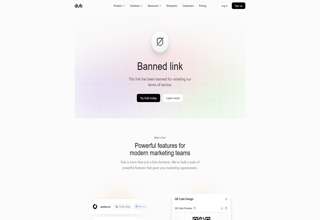

phishing__activmembrship_com__homepage.png | size: (1920, 1080)


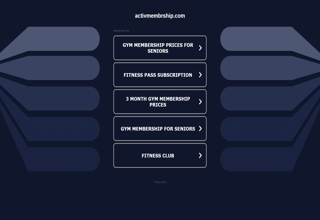

phishing__ai_website_builder__login.png | size: (1920, 1080)


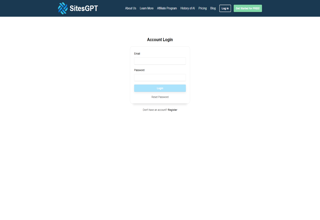


legitimate_images
Images found: 50
Valid images: 50
Invalid images: 0
legitimate__111_wales_nhs_uk__homepage.png | size: (1920, 1080)


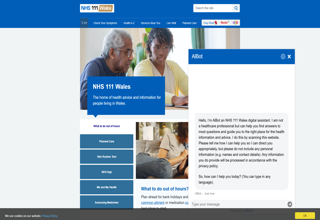

legitimate__a_star_organisation_structure__homepage.png | size: (1920, 1080)


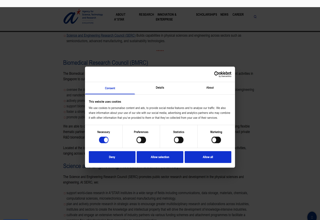

legitimate__ability_connection_colorado__homepage.png | size: (1920, 1080)


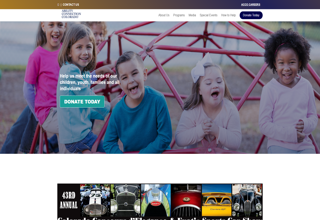

In [ ]:

from PIL import Image
from IPython.display import display
import random

# Count valid images in each pilot folder
extensions = {".png", ".jpg", ".jpeg", ".webp"}

for label in ["phishing_websites", "legitimate_images"]:
    folder = RAW_DIR / label
    files = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    valid = []
    invalid = []

    for path in files:
        try:
            with Image.open(path) as im:
                im.verify()
            valid.append(path)
        except Exception:
            invalid.append(path)

    print(f"\n{label}")
    print("Images found:", len(files))
    print("Valid images:", len(valid))
    print("Invalid images:", len(invalid))

    # Display 3 examples
    for path in random.sample(valid, min(3, len(valid))):
        with Image.open(path) as im:
            print(path.name, "| size:", im.size)
            display(im.copy().convert("RGB").resize((320, 220)))


In [ ]:

from pathlib import Path

extensions = {".png", ".jpg", ".jpeg", ".webp"}

print("SCAMUNDO IMAGE DATASET STATUS\n")

total = 0

for label in CLASSES:
    folder = RAW_DIR / label
    count = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    total += count
    print(f"{label:28s}: {count:4d} images")

print("-" * 43)
print(f"{'TOTAL':28s}: {total:4d} images")


SCAMUNDO IMAGE DATASET STATUS

phishing_websites           :   50 images
fake_payment_receipts       :    0 images
qr_payment_scams            :    0 images
scam_sms_chats              :    0 images
job_task_scams              :    0 images
lottery_prize_scams         :    0 images
impersonation_scams         :    0 images
legitimate_images           :   50 images
-------------------------------------------
TOTAL                       :  100 images


In [ ]:

import pandas as pd

# Create a dataset collection log
LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"
LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

columns = [
    "filename",
    "class_label",
    "source",
    "source_url_or_id",
    "label_evidence",
    "synthetic_or_real",
    "review_status"
]

if LOG_PATH.exists():
    manifest = pd.read_csv(LOG_PATH)
else:
    manifest = pd.DataFrame(columns=columns)

manifest.to_csv(LOG_PATH, index=False)

print("Manifest saved to:", LOG_PATH)
print("Existing records:", len(manifest))
print("Ready to record image sources and labels.")


Manifest saved to: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_manifest.csv
Existing records: 0
Ready to record image sources and labels.


In [ ]:

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
import pandas as pd
import textwrap

# Destination and manifest
OUT_DIR = RAW_DIR / "scam_sms_chats"
OUT_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"

# Synthetic examples: deliberately use placeholders, not real links
examples = [
    ("bank_kyc", "Bank Alert",
     "Your account may be restricted. Verify your KYC immediately using the link provided by the sender."),
    ("upi_refund", "Payment Support",
     "Your refund is pending. Follow these instructions to claim it. Never share this message without checking the source."),
    ("lottery_prize", "Prize Centre",
     "Congratulations! You have supposedly won a large prize. Pay a processing fee before claiming it."),
    ("job_fee", "Recruitment Team",
     "You have been selected for a job. Pay a registration fee before receiving your offer letter."),
    ("task_scam", "Online Task Team",
     "Complete prepaid tasks and deposit more money to unlock your promised earnings."),
    ("delivery_fee", "Delivery Notice",
     "Your parcel is supposedly on hold. Pay an unexpected fee using the sender's requested payment method."),
    ("account_threat", "Account Security",
     "Your account will supposedly be closed today. The sender asks you to act urgently through an unverified link."),
    ("impersonation", "Customer Support",
     "I am contacting you from support. Share your verification code so I can fix your account."),
    ("electricity_threat", "Utility Notice",
     "Your electricity will supposedly be disconnected soon unless you make an immediate payment."),
    ("urgent_money", "Known Contact",
     "I urgently need money. Please transfer it now and do not call me to confirm.")
]

# Fonts available in typical Colab environments
try:
    title_font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 23)
    body_font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 19)
    small_font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 14)
except OSError:
    title_font = body_font = small_font = ImageFont.load_default()

def wrap_by_pixels(draw, text, font, max_width):
    words = text.split()
    lines, current = [], ""

    for word in words:
        trial = f"{current} {word}".strip()
        if draw.textbbox((0, 0), trial, font=font)[2] <= max_width:
            current = trial
        else:
            if current:
                lines.append(current)
            current = word

    if current:
        lines.append(current)
    return lines

manifest_rows = []

for key, sender, message in examples:
    width, height = 720, 520
    img = Image.new("RGB", (width, height), "#F1F3F5")
    draw = ImageDraw.Draw(img)

    # Generic fictional chat interface
    draw.rectangle((0, 0, width, 76), fill="#234B70")
    draw.text((25, 14), "Example Chat", font=title_font, fill="white")
    draw.text((25, 47), "SYNTHETIC TRAINING EXAMPLE", font=small_font, fill="#E4EEF7")

    draw.rounded_rectangle((22, 105, 490, 157), radius=14, fill="white")
    draw.text((38, 118), sender, font=title_font, fill="#234B70")

    lines = wrap_by_pixels(draw, message, body_font, 410)
    bubble_height = max(100, 36 + len(lines) * 30)
    draw.rounded_rectangle(
        (22, 175, 505, 175 + bubble_height),
        radius=18,
        fill="white",
        outline="#D5DCE3",
        width=2
    )

    y = 194
    for line in lines:
        draw.text((40, y), line, font=body_font, fill="#222222")
        y += 30

    draw.text(
        (22, height - 55),
        "Illustrative scam pattern — verify context and sender.",
        font=small_font,
        fill="#555555"
    )
    draw.text(
        (22, height - 30),
        "Not a real conversation or proof of an actual scam.",
        font=small_font,
        fill="#555555"
    )

    filename = f"synthetic_{key}.png"
    img.save(OUT_DIR / filename)

    manifest_rows.append({
        "filename": filename,
        "class_label": "scam_sms_chats",
        "source": "Synthetic example generated for Scamundo pilot",
        "source_url_or_id": "scamundo_synthetic_chat_v1",
        "label_evidence": "Authored illustrative scam pattern; requires human review",
        "synthetic_or_real": "synthetic",
        "review_status": "needs human review"
    })

# Append records without deleting previous manifest entries
if LOG_PATH.exists():
    manifest = pd.read_csv(LOG_PATH)
else:
    manifest = pd.DataFrame(columns=[
        "filename", "class_label", "source", "source_url_or_id",
        "label_evidence", "synthetic_or_real", "review_status"
    ])

new_records = pd.DataFrame(manifest_rows)
manifest = pd.concat(
    [manifest, new_records],
    ignore_index=True
).drop_duplicates(
    subset=["class_label", "filename"],
    keep="last"
)

manifest.to_csv(LOG_PATH, index=False)

print("Synthetic chat screenshots created:", len(examples))
print("Saved in:", OUT_DIR)
print("Manifest updated:", LOG_PATH)
print("Remember: these are illustrative examples, not real-world evidence.")


Synthetic chat screenshots created: 10
Saved in: /content/drive/MyDrive/Scamundo_Image_Module/raw/scam_sms_chats
Manifest updated: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_manifest.csv
Remember: these are illustrative examples, not real-world evidence.


Synthetic chat images found: 10
synthetic_account_threat.png


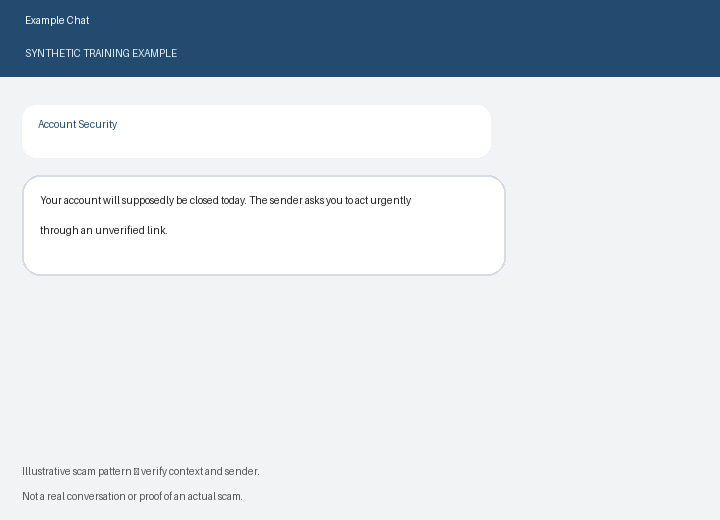

synthetic_bank_kyc.png


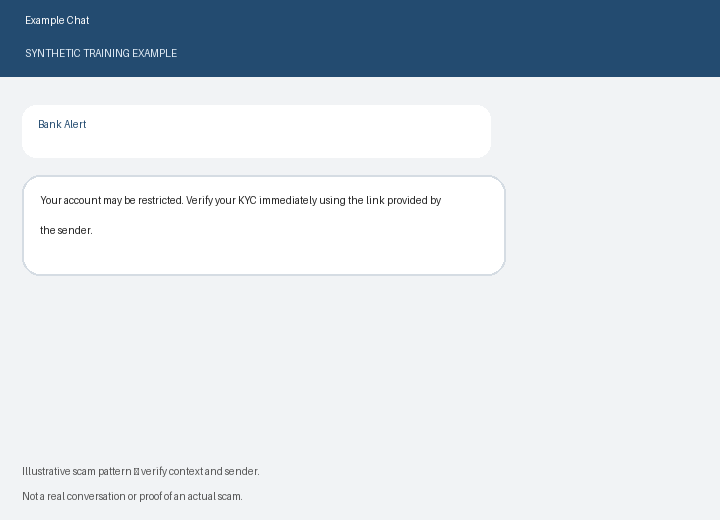

synthetic_delivery_fee.png


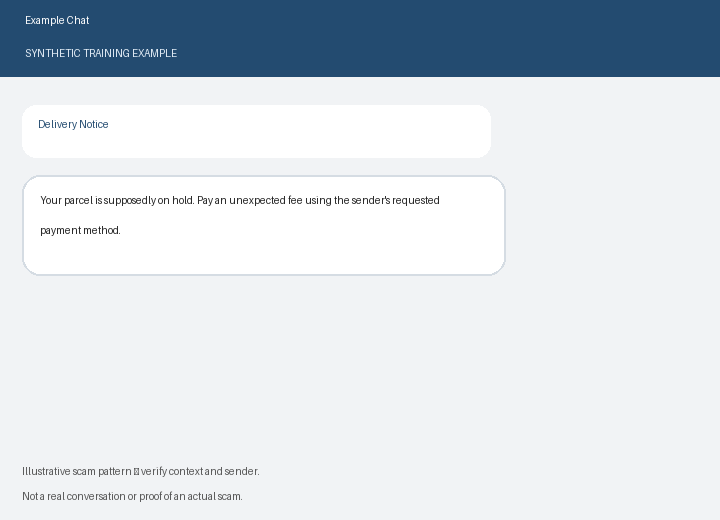

In [ ]:

from IPython.display import display
from PIL import Image

preview_files = sorted(OUT_DIR.glob("synthetic_*.png"))

print("Synthetic chat images found:", len(preview_files))

for path in preview_files[:3]:
    print(path.name)
    display(Image.open(path))


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd
import random
import textwrap

# Re-create paths if your Colab runtime has restarted
PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"
REPORT_DIR = PROJECT_DIR / "reports"

RECEIPT_DIR = RAW_DIR / "fake_payment_receipts"
RECEIPT_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = REPORT_DIR / "image_dataset_manifest.csv"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Keep the manifest's existing schema
columns = [
    "filename", "class_label", "source", "source_url_or_id",
    "label_evidence", "synthetic_or_real", "review_status"
]

if LOG_PATH.exists():
    manifest = pd.read_csv(LOG_PATH)
else:
    manifest = pd.DataFrame(columns=columns)

# Synthetic receipt designs; fictional data only
examples = [
    ("receipt_pending.png", "PAYMENT PENDING", "₹2,499.00",
     "Status does not confirm payment"),
    ("receipt_fake_success.png", "PAYMENT SUCCESSFUL", "₹5,000.00",
     "Synthetic success screen; not a real transaction"),
    ("receipt_wrong_amount.png", "PAYMENT SUCCESSFUL", "₹99,999.00",
     "Fictional amount for visual testing"),
    ("receipt_refund_claim.png", "REFUND INITIATED", "₹1,250.00",
     "Synthetic refund claim"),
    ("receipt_qr_transfer.png", "TRANSFER COMPLETE", "₹750.00",
     "Fictional transfer confirmation"),
    ("receipt_duplicate_id.png", "PAYMENT SUCCESSFUL", "₹3,200.00",
     "Fictional duplicate-style transaction ID"),
    ("receipt_unverified.png", "TRANSACTION DETAILS", "₹8,500.00",
     "Unverified synthetic receipt design"),
    ("receipt_wallet_credit.png", "WALLET CREDITED", "₹4,000.00",
     "Fictional wallet notification"),
    ("receipt_bank_transfer.png", "BANK TRANSFER", "₹12,000.00",
     "Synthetic bank-transfer confirmation"),
    ("receipt_editable_style.png", "PAYMENT SUCCESSFUL", "₹6,750.00",
     "Illustrative receipt with generic fields"),
]

def get_font(size):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]
    for path in candidates:
        if Path(path).exists():
            return ImageFont.truetype(path, size)
    return ImageFont.load_default()

title_font = get_font(27)
body_font = get_font(19)
small_font = get_font(14)

new_rows = []

for filename, status, amount, evidence in examples:
    path = RECEIPT_DIR / filename

    # Avoid overwriting a file that already exists
    if path.exists():
        print(f"Skipping existing file: {filename}")
        continue

    img = Image.new("RGB", (720, 900), "#f3f5f8")
    draw = ImageDraw.Draw(img)

    # Generic, fictional payment receipt — no real company branding
    draw.rounded_rectangle(
        (45, 40, 675, 855), radius=24,
        fill="white", outline="#d7dce3", width=3
    )
    draw.rounded_rectangle(
        (45, 40, 675, 145), radius=24, fill="#263b63"
    )
    draw.rectangle((45, 115, 675, 145), fill="#263b63")

    draw.text((80, 72), "PAYMENT RECEIPT", font=title_font, fill="white")
    draw.text((80, 180), "DEMO IMAGE • SYNTHETIC", font=small_font,
              fill="#a12626")

    draw.text((80, 230), status, font=title_font, fill="#263b63")
    draw.text((80, 295), "Amount", font=body_font, fill="#5a6472")
    draw.text((80, 330), amount, font=get_font(38), fill="#172033")

    draw.line((80, 400, 640, 400), fill="#d7dce3", width=2)

    details = [
        ("Recipient", "Example User"),
        ("Payment method", "Demo payment"),
        ("Transaction ID", "DEMO-" + str(random.randint(100000, 999999))),
        ("Date", "01 Jan 2026"),
        ("Reference", "NOT A REAL TRANSACTION"),
    ]

    y = 435
    for label, value in details:
        draw.text((80, y), label, font=small_font, fill="#697386")
        draw.text((300, y), value, font=body_font, fill="#172033")
        y += 58

    draw.rounded_rectangle(
        (80, 740, 640, 795), radius=12,
        fill="#fff0f0", outline="#e4aaaa", width=2
    )
    draw.text((103, 758), "SYNTHETIC SAMPLE — NOT PROOF OF PAYMENT",
              font=small_font, fill="#a12626")

    img.save(path)

    new_rows.append({
        "filename": filename,
        "class_label": "fake_payment_receipts",
        "source": "Scamundo synthetic generator",
        "source_url_or_id": "scamundo_synthetic_receipt_v1",
        "label_evidence": evidence,
        "synthetic_or_real": "synthetic",
        "review_status": "needs human review",
    })

if new_rows:
    manifest = pd.concat(
        [manifest, pd.DataFrame(new_rows, columns=columns)],
        ignore_index=True
    )
    manifest = manifest.drop_duplicates(
        subset=["filename", "class_label", "source_url_or_id"],
        keep="last"
    )
    manifest.to_csv(LOG_PATH, index=False)

print("Receipt folder:", RECEIPT_DIR)
print("New synthetic receipts created:", len(new_rows))
print("Total files in receipt folder:",
      len(list(RECEIPT_DIR.glob("*.png"))))
print("Manifest saved:", LOG_PATH)


Receipt folder: /content/drive/MyDrive/Scamundo_Image_Module/raw/fake_payment_receipts
New synthetic receipts created: 10
Total files in receipt folder: 10
Manifest saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_manifest.csv


Receipt images found: 10
receipt_bank_transfer.png


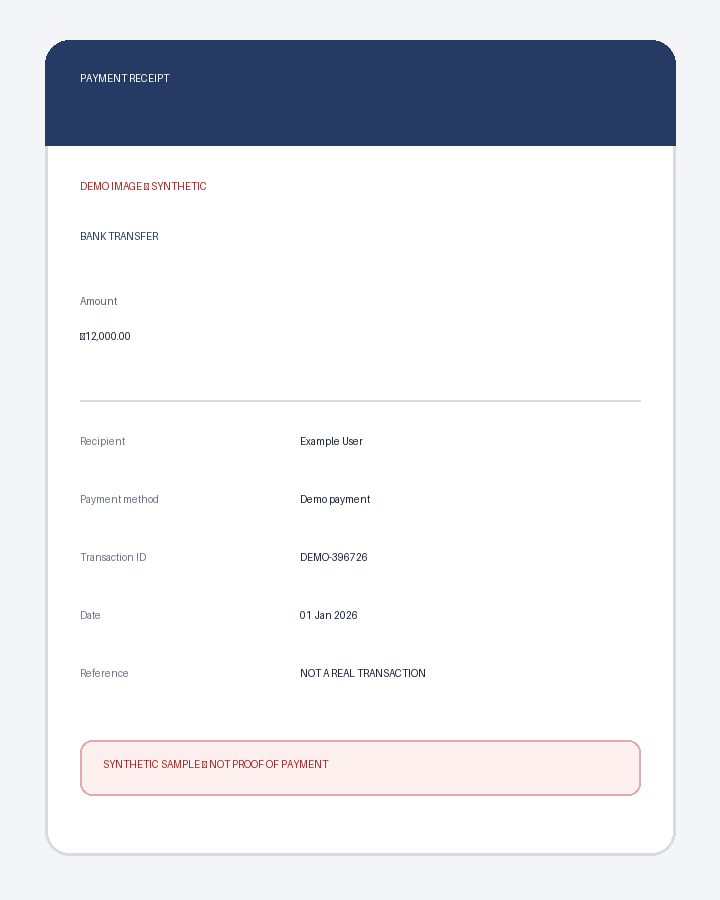

receipt_duplicate_id.png


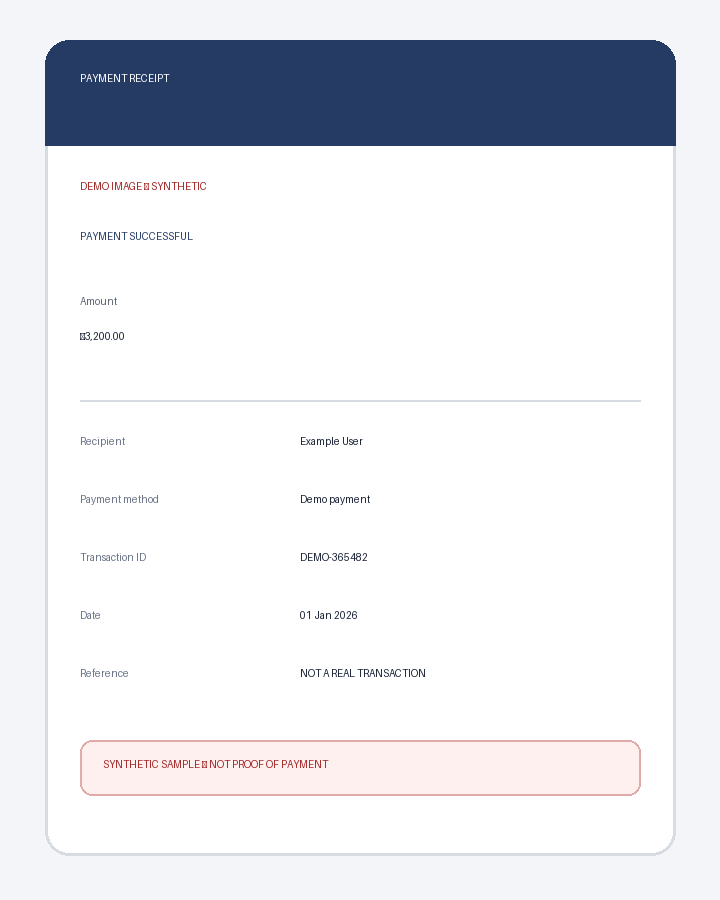

receipt_editable_style.png


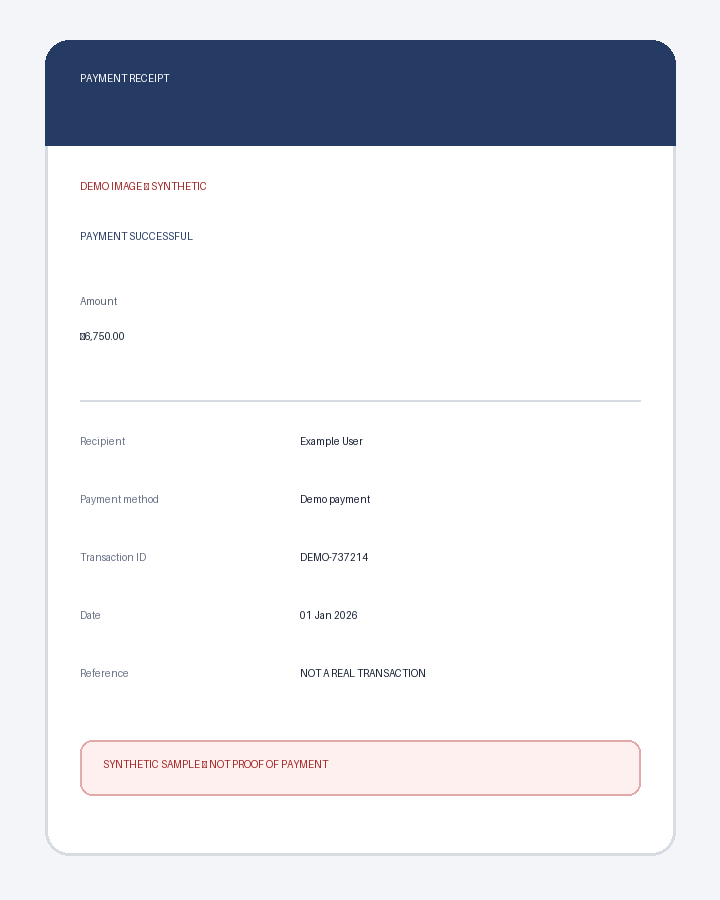

,filename,class_label,source,source_url_or_id,label_evidence,synthetic_or_real,review_status
10,receipt_pending.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Status does not confirm payment,synthetic,needs human review
11,receipt_fake_success.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Synthetic success screen; not a real transaction,synthetic,needs human review
12,receipt_wrong_amount.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Fictional amount for visual testing,synthetic,needs human review
13,receipt_refund_claim.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Synthetic refund claim,synthetic,needs human review
14,receipt_qr_transfer.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Fictional transfer confirmation,synthetic,needs human review
15,receipt_duplicate_id.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Fictional duplicate-style transaction ID,synthetic,needs human review
16,receipt_unverified.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Unverified synthetic receipt design,synthetic,needs human review
17,receipt_wallet_credit.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Fictional wallet notification,synthetic,needs human review
18,receipt_bank_transfer.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Synthetic bank-transfer confirmation,synthetic,needs human review
19,receipt_editable_style.png,fake_payment_receipts,Scamundo synthetic generator,scamundo_synthetic_receipt_v1,Illustrative receipt with generic fields,synthetic,needs human review


In [ ]:

from IPython.display import display
from PIL import Image
import pandas as pd

receipt_files = sorted(RECEIPT_DIR.glob("*.png"))

print("Receipt images found:", len(receipt_files))

for path in receipt_files[:3]:
    print(path.name)
    display(Image.open(path))

manifest = pd.read_csv(LOG_PATH)
receipt_rows = manifest[
    (manifest["class_label"] == "fake_payment_receipts") &
    (manifest["source_url_or_id"] == "scamundo_synthetic_receipt_v1")
]

display(receipt_rows.tail(10))


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd
import random

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
QR_DIR = PROJECT_DIR / "raw" / "qr_payment_scams"
REPORT_DIR = PROJECT_DIR / "reports"
LOG_PATH = REPORT_DIR / "image_dataset_manifest.csv"

QR_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "filename", "class_label", "source", "source_url_or_id",
    "label_evidence", "synthetic_or_real", "review_status"
]

if LOG_PATH.exists():
    manifest = pd.read_csv(LOG_PATH)
else:
    manifest = pd.DataFrame(columns=columns)

def get_font(size):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]
    for p in candidates:
        if Path(p).exists():
            return ImageFont.truetype(p, size)
    return ImageFont.load_default()

font_title = get_font(27)
font_body = get_font(19)
font_small = get_font(15)

scenarios = [
    ("qr_receive_money.png", "SCAN TO RECEIVE MONEY",
     "A message claims scanning a QR code is required to receive money."),
    ("qr_refund_claim.png", "REFUND QR REQUEST",
     "A fictional seller asks a customer to scan a code for a refund."),
    ("qr_prize_claim.png", "CLAIM YOUR PRIZE",
     "A prize message demands QR scanning before a reward is released."),
    ("qr_job_payment.png", "JOB VERIFICATION",
     "A fictional recruiter asks the applicant to scan a payment QR."),
    ("qr_urgent_transfer.png", "URGENT PAYMENT",
     "An urgent message requests a QR-based transfer."),
    ("qr_account_unblock.png", "UNBLOCK ACCOUNT",
     "A message claims QR scanning is needed to restore account access."),
    ("qr_delivery_fee.png", "DELIVERY FEE",
     "A fictional delivery notice requests an unexpected payment."),
    ("qr_support_impersonation.png", "CUSTOMER SUPPORT",
     "An unverified support message asks for QR payment."),
    ("qr_marketplace_seller.png", "MARKETPLACE PAYMENT",
     "A fictional buyer or seller sends a suspicious QR payment request."),
    ("qr_unknown_sender.png", "UNKNOWN SENDER",
     "An unknown contact sends an unexplained QR payment request."),
]

new_rows = []

for filename, heading, scenario in scenarios:
    path = QR_DIR / filename

    if path.exists():
        print("Skipping existing file:", filename)
        continue

    img = Image.new("RGB", (720, 900), "#f2f5f9")
    draw = ImageDraw.Draw(img)

    draw.rounded_rectangle(
        (40, 35, 680, 865), radius=24,
        fill="white", outline="#d3dbe5", width=3
    )
    draw.rounded_rectangle(
        (40, 35, 680, 140), radius=24, fill="#273c65"
    )
    draw.rectangle((40, 110, 680, 140), fill="#273c65")

    draw.text((75, 70), heading, font=font_title, fill="white")
    draw.text((75, 165), "SYNTHETIC SCAM SCENARIO",
              font=font_small, fill="#a12626")

    # Decorative placeholder only; deliberately not a scannable QR code
    x0, y0, cell = 250, 235, 22
    random.seed(filename)
    for r in range(7):
        for c in range(7):
            if random.random() > 0.45:
                x, y = x0 + c * cell, y0 + r * cell
                draw.rectangle(
                    (x, y, x + cell - 3, y + cell - 3),
                    fill="#26364d"
                )

    draw.rounded_rectangle(
        (90, 430, 630, 610), radius=16,
        fill="#f7f9fc", outline="#d8dee8", width=2
    )

    draw.text((115, 455), "Example message:", font=font_body,
              fill="#273c65")

    words = scenario.split()
    lines, current = [], ""
    for word in words:
        test = (current + " " + word).strip()
        if draw.textbbox((0, 0), test, font=font_body)[2] > 480:
            lines.append(current)
            current = word
        else:
            current = test
    if current:
        lines.append(current)

    y = 495
    for line in lines[:4]:
        draw.text((115, y), line, font=font_body, fill="#28313f")
        y += 30

    draw.rounded_rectangle(
        (90, 660, 630, 730), radius=12,
        fill="#fff0f0", outline="#e1aaaa", width=2
    )
    draw.text((115, 682), "Never pay or share credentials blindly",
              font=font_small, fill="#a12626")

    draw.text((90, 790), "Illustrative image — not a real QR code",
              font=font_small, fill="#596579")

    img.save(path)

    new_rows.append({
        "filename": filename,
        "class_label": "qr_payment_scams",
        "source": "Scamundo synthetic generator",
        "source_url_or_id": "scamundo_synthetic_qr_v1",
        "label_evidence": scenario,
        "synthetic_or_real": "synthetic",
        "review_status": "needs human review",
    })

if new_rows:
    manifest = pd.concat(
        [manifest, pd.DataFrame(new_rows, columns=columns)],
        ignore_index=True
    )
    manifest = manifest.drop_duplicates(
        subset=["filename", "class_label", "source_url_or_id"],
        keep="last"
    )
    manifest.to_csv(LOG_PATH, index=False)

print("QR folder:", QR_DIR)
print("New images created:", len(new_rows))
print("Total QR images:", len(list(QR_DIR.glob("*.png"))))
print("Manifest saved:", LOG_PATH)


QR folder: /content/drive/MyDrive/Scamundo_Image_Module/raw/qr_payment_scams
New images created: 10
Total QR images: 10
Manifest saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_manifest.csv


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
JOB_DIR = PROJECT_DIR / "raw" / "job_task_scams"
REPORT_DIR = PROJECT_DIR / "reports"
LOG_PATH = REPORT_DIR / "image_dataset_manifest.csv"

JOB_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "filename", "class_label", "source", "source_url_or_id",
    "label_evidence", "synthetic_or_real", "review_status"
]

manifest = (
    pd.read_csv(LOG_PATH)
    if LOG_PATH.exists()
    else pd.DataFrame(columns=columns)
)

def get_font(size):
    for p in [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]:
        if Path(p).exists():
            return ImageFont.truetype(p, size)
    return ImageFont.load_default()

title_font = get_font(27)
body_font = get_font(19)
small_font = get_font(15)

scenarios = [
    ("job_registration_fee.png", "REMOTE JOB OFFER",
     "Pay a registration fee before your job application can proceed."),
    ("task_unlock_fee.png", "TASK REWARD",
     "Deposit money to unlock the next set of paid tasks."),
    ("job_training_payment.png", "PAID TRAINING",
     "Send an upfront payment to access mandatory training."),
    ("rating_task_scheme.png", "ONLINE RATING TASK",
     "Complete rating tasks and pay to withdraw the displayed reward."),
    ("salary_release_fee.png", "SALARY RELEASE",
     "Pay a processing charge before your first salary is released."),
    ("work_from_home_offer.png", "WORK FROM HOME",
     "A suspicious offer promises unusually high income for easy work."),
    ("recruiter_impersonation.png", "RECRUITER MESSAGE",
     "An unverified recruiter requests sensitive details or money."),
    ("task_recharge_request.png", "TASK ACCOUNT RECHARGE",
     "Recharge an account to continue completing paid tasks."),
    ("guaranteed_income_offer.png", "GUARANTEED INCOME",
     "A message guarantees large earnings with little effort."),
    ("withdrawal_blocked.png", "WITHDRAWAL BLOCKED",
     "A platform demands another deposit before allowing withdrawal."),
]

new_rows = []

for filename, heading, message in scenarios:
    path = JOB_DIR / filename

    if path.exists():
        print("Skipping existing file:", filename)
        continue

    img = Image.new("RGB", (720, 900), "#f3f5f8")
    draw = ImageDraw.Draw(img)

    draw.rounded_rectangle(
        (40, 35, 680, 865), radius=24,
        fill="white", outline="#d5dce6", width=3
    )
    draw.rounded_rectangle(
        (40, 35, 680, 145), radius=24, fill="#293e67"
    )
    draw.rectangle((40, 115, 680, 145), fill="#293e67")

    draw.text((75, 72), heading, font=title_font, fill="white")
    draw.text((75, 175), "FICTIONAL JOB/TASK SCENARIO",
              font=small_font, fill="#a12626")

    draw.text((75, 245), "Example message", font=body_font,
              fill="#293e67")

    draw.rounded_rectangle(
        (75, 290, 645, 505), radius=16,
        fill="#f7f9fc", outline="#dce2eb", width=2
    )

    # Wrap message into lines
    words = message.split()
    lines, current = [], ""
    for word in words:
        candidate = (current + " " + word).strip()
        if draw.textbbox((0, 0), candidate, font=body_font)[2] > 510:
            lines.append(current)
            current = word
        else:
            current = candidate
    if current:
        lines.append(current)

    y = 325
    for line in lines[:5]:
        draw.text((100, y), line, font=body_font, fill="#26313f")
        y += 38

    draw.rounded_rectangle(
        (75, 565, 645, 685), radius=16,
        fill="#fff3e8", outline="#edc7a3", width=2
    )
    draw.text((100, 585), "Warning signs to investigate:",
              font=body_font, fill="#8c4515")
    draw.text((100, 625), "Upfront fees • Pressure • Unrealistic rewards",
              font=small_font, fill="#8c4515")

    draw.text((75, 760), "SYNTHETIC SAMPLE — NOT A REAL JOB OFFER",
              font=small_font, fill="#a12626")

    img.save(path)

    new_rows.append({
        "filename": filename,
        "class_label": "job_task_scams",
        "source": "Scamundo synthetic generator",
        "source_url_or_id": "scamundo_synthetic_job_v1",
        "label_evidence": message,
        "synthetic_or_real": "synthetic",
        "review_status": "needs human review",
    })

if new_rows:
    manifest = pd.concat(
        [manifest, pd.DataFrame(new_rows, columns=columns)],
        ignore_index=True
    )
    manifest = manifest.drop_duplicates(
        subset=["filename", "class_label", "source_url_or_id"],
        keep="last"
    )
    manifest.to_csv(LOG_PATH, index=False)

print("Job/task folder:", JOB_DIR)
print("New images created:", len(new_rows))
print("Total job/task images:", len(list(JOB_DIR.glob("*.png"))))
print("Manifest saved:", LOG_PATH)


Job/task folder: /content/drive/MyDrive/Scamundo_Image_Module/raw/job_task_scams
New images created: 10
Total job/task images: 10
Manifest saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_manifest.csv


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
LOTTERY_DIR = PROJECT_DIR / "raw" / "lottery_prize_scams"
REPORT_DIR = PROJECT_DIR / "reports"
LOG_PATH = REPORT_DIR / "image_dataset_manifest.csv"

LOTTERY_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "filename", "class_label", "source", "source_url_or_id",
    "label_evidence", "synthetic_or_real", "review_status"
]

manifest = (
    pd.read_csv(LOG_PATH)
    if LOG_PATH.exists()
    else pd.DataFrame(columns=columns)
)

def get_font(size):
    for p in [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]:
        if Path(p).exists():
            return ImageFont.truetype(p, size)
    return ImageFont.load_default()

title_font = get_font(27)
body_font = get_font(19)
small_font = get_font(15)

scenarios = [
    ("lottery_winner.png", "LOTTERY WINNER",
     "You have supposedly won a lottery you never entered."),
    ("prize_claim_fee.png", "PRIZE CLAIM",
     "Pay a fee before a fictional prize can be delivered."),
    ("giveaway_winner.png", "GIVEAWAY WINNER",
     "An unknown account says you won a giveaway and asks for payment."),
    ("tax_release_fee.png", "PRIZE TAX PAYMENT",
     "Send money upfront to release a claimed prize."),
    ("lucky_draw_message.png", "LUCKY DRAW",
     "A message claims your phone number was selected in a draw."),
    ("customs_prize_fee.png", "PRIZE DELIVERY",
     "A sender demands an unexpected delivery or customs charge."),
    ("claim_deadline.png", "URGENT PRIZE CLAIM",
     "A message pressures you to claim a reward immediately."),
    ("bank_details_prize.png", "VERIFY WINNINGS",
     "A supposed prize agent requests sensitive banking information."),
    ("crypto_reward.png", "REWARD BONUS",
     "A fictional reward requires an upfront cryptocurrency payment."),
    ("unknown_prize_sender.png", "UNKNOWN PRIZE NOTICE",
     "An unknown sender announces an unverified cash reward."),
]

new_rows = []

for filename, heading, message in scenarios:
    path = LOTTERY_DIR / filename

    if path.exists():
        print("Skipping existing file:", filename)
        continue

    img = Image.new("RGB", (720, 900), "#f3f5f8")
    draw = ImageDraw.Draw(img)

    draw.rounded_rectangle(
        (40, 35, 680, 865), radius=24,
        fill="white", outline="#d5dce6", width=3
    )
    draw.rounded_rectangle(
        (40, 35, 680, 145), radius=24, fill="#60417d"
    )
    draw.rectangle((40, 115, 680, 145), fill="#60417d")

    draw.text((75, 72), heading, font=title_font, fill="white")
    draw.text((75, 175), "FICTIONAL PRIZE SCENARIO",
              font=small_font, fill="#a12626")

    draw.text((75, 245), "Example message", font=body_font,
              fill="#60417d")

    draw.rounded_rectangle(
        (75, 290, 645, 515), radius=16,
        fill="#faf7fd", outline="#e1d6ed", width=2
    )

    words = message.split()
    lines, current = [], ""
    for word in words:
        candidate = (current + " " + word).strip()
        if draw.textbbox((0, 0), candidate, font=body_font)[2] > 510:
            lines.append(current)
            current = word
        else:
            current = candidate
    if current:
        lines.append(current)

    y = 325
    for line in lines[:5]:
        draw.text((100, y), line, font=body_font, fill="#30263a")
        y += 38

    draw.rounded_rectangle(
        (75, 570, 645, 690), radius=16,
        fill="#fff3e8", outline="#edc7a3", width=2
    )
    draw.text((100, 590), "Warning signs to investigate:",
              font=body_font, fill="#8c4515")
    draw.text((100, 630), "Unexpected win • Upfront fee • Urgency",
              font=small_font, fill="#8c4515")

    draw.text((75, 760), "SYNTHETIC SAMPLE — NOT A REAL PRIZE",
              font=small_font, fill="#a12626")

    img.save(path)

    new_rows.append({
        "filename": filename,
        "class_label": "lottery_prize_scams",
        "source": "Scamundo synthetic generator",
        "source_url_or_id": "scamundo_synthetic_lottery_v1",
        "label_evidence": message,
        "synthetic_or_real": "synthetic",
        "review_status": "needs human review",
    })

if new_rows:
    manifest = pd.concat(
        [manifest, pd.DataFrame(new_rows, columns=columns)],
        ignore_index=True
    )
    manifest = manifest.drop_duplicates(
        subset=["filename", "class_label", "source_url_or_id"],
        keep="last"
    )
    manifest.to_csv(LOG_PATH, index=False)

print("Lottery/prize folder:", LOTTERY_DIR)
print("New images created:", len(new_rows))
print("Total lottery/prize images:",
      len(list(LOTTERY_DIR.glob("*.png"))))
print("Manifest saved:", LOG_PATH)


Lottery/prize folder: /content/drive/MyDrive/Scamundo_Image_Module/raw/lottery_prize_scams
New images created: 10
Total lottery/prize images: 10
Manifest saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_manifest.csv


In [ ]:

from pathlib import Path
from PIL import Image
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"
LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

valid_extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
manifest = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else pd.DataFrame()

summary = []
invalid_images = []
unlogged_images = []

for class_name in CLASSES:
    folder = RAW_DIR / class_name
    files = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in valid_extensions
    ]

    valid_count = 0
    for path in files:
        try:
            with Image.open(path) as im:
                im.verify()
            valid_count += 1
        except Exception:
            invalid_images.append(str(path))

        if not manifest.empty:
            matches = manifest[
                (manifest["filename"] == path.name) &
                (manifest["class_label"] == class_name)
            ]
            if matches.empty:
                unlogged_images.append(str(path))

    summary.append({
        "class_label": class_name,
        "files_found": len(files),
        "valid_images": valid_count,
        "invalid_images": len(files) - valid_count,
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

print("Total image files:", int(summary_df["files_found"].sum()))
print("Total valid images:", int(summary_df["valid_images"].sum()))
print("Unreadable images:", len(invalid_images))
print("Images missing manifest entries:", len(unlogged_images))

if invalid_images:
    print("\nUnreadable image paths:")
    for p in invalid_images:
        print(p)

if unlogged_images:
    print("\nImages missing manifest entries:")
    for p in unlogged_images:
        print(p)

if not manifest.empty and "synthetic_or_real" in manifest.columns:
    print("\nManifest data-type counts:")
    display(manifest["synthetic_or_real"].value_counts(dropna=False))

    print("\nManifest review-status counts:")
    display(manifest["review_status"].value_counts(dropna=False))


,class_label,files_found,valid_images,invalid_images
0,phishing_websites,50,50,0
1,fake_payment_receipts,10,10,0
2,qr_payment_scams,10,10,0
3,scam_sms_chats,10,10,0
4,job_task_scams,10,10,0
5,lottery_prize_scams,10,10,0
6,impersonation_scams,0,0,0
7,legitimate_images,50,50,0


Total image files: 150
Total valid images: 150
Unreadable images: 0
Images missing manifest entries: 100

Images missing manifest entries:
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__02_jpg_260_270__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__0btu8g_icu__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__2no__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__3118__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__404__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__404_error_page__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__40htw_landing_pages__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__5x_to__homepage.png
/content/drive/MyDrive/Scamundo_Image_Module/raw/phis

,count
synthetic_or_real,
synthetic,50



Manifest review-status counts:


,count
review_status,
needs human review,50


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"

for folder_name in [
    "impersonation_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
]:
    folder = RAW_DIR / folder_name
    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
    ]
    print(f"\n{folder_name}: {len(images)} images")
    for p in images[:3]:
        print("  ", p.name)

# Search for the expected impersonation images anywhere in raw/
print("\nSearching for misplaced impersonation files...")
for p in RAW_DIR.rglob("fake_bank_alert.png"):
    print("Found:", p)



impersonation_scams: 0 images

scam_sms_chats: 10 images
   synthetic_bank_kyc.png
   synthetic_upi_refund.png
   synthetic_lottery_prize.png

job_task_scams: 10 images
   job_registration_fee.png
   task_unlock_fee.png
   job_training_payment.png

lottery_prize_scams: 10 images
   lottery_winner.png
   prize_claim_fee.png
   giveaway_winner.png

Searching for misplaced impersonation files...


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"
LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"

columns = [
    "filename", "class_label", "source", "source_url_or_id",
    "label_evidence", "synthetic_or_real", "review_status"
]

if LOG_PATH.exists():
    manifest = pd.read_csv(LOG_PATH)
else:
    manifest = pd.DataFrame(columns=columns)

# Use the dataset repository from the earlier collection step.
repo_id = "shresthsamyak/phishing-website-screenshots"

new_rows = []

for class_name in ["phishing_websites", "legitimate_images"]:
    folder = RAW_DIR / class_name

    for path in folder.rglob("*"):
        if not path.is_file():
            continue
        if path.suffix.lower() not in {".png", ".jpg", ".jpeg", ".webp", ".bmp"}:
            continue

        new_rows.append({
            "filename": path.name,
            "class_label": class_name,
            "source": "Hugging Face dataset",
            "source_url_or_id": repo_id,
            "label_evidence": (
                "Source dataset folder and assigned class; "
                "individual image label not independently verified"
            ),
            "synthetic_or_real": "downloaded; real-world status unverified",
            "review_status": "needs human review",
        })

if new_rows:
    additions = pd.DataFrame(new_rows, columns=columns)
    manifest = pd.concat([manifest, additions], ignore_index=True)

    manifest = manifest.drop_duplicates(
        subset=["filename", "class_label", "source_url_or_id"],
        keep="first"
    )

    manifest.to_csv(LOG_PATH, index=False)

print("Manifest saved:", LOG_PATH)
print("Manifest rows:", len(manifest))
print("\nRecords by class:")
print(manifest["class_label"].value_counts().sort_index())
print("\nRecords by data type:")
print(manifest["synthetic_or_real"].value_counts(dropna=False))


Manifest saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_manifest.csv
Manifest rows: 150

Records by class:
class_label
fake_payment_receipts    10
job_task_scams           10
legitimate_images        50
lottery_prize_scams      10
phishing_websites        50
qr_payment_scams         10
scam_sms_chats           10
Name: count, dtype: int64

Records by data type:
synthetic_or_real
downloaded; real-world status unverified    100
synthetic                                    50
Name: count, dtype: int64


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"
OUT_DIR = RAW_DIR / "impersonation_scams"
LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"

OUT_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "filename", "class_label", "source", "source_url_or_id",
    "label_evidence", "synthetic_or_real", "review_status"
]

manifest = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else pd.DataFrame(columns=columns)

def get_font(size):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    ]
    for font_path in candidates:
        if Path(font_path).exists():
            return ImageFont.truetype(font_path, size)
    return ImageFont.load_default()

title_font = get_font(25)
body_font = get_font(19)
small_font = get_font(14)

scenarios = [
    ("fake_bank_alert.png", "BANK SECURITY ALERT",
     "An unverified sender claims to represent a bank and requests account verification."),
    ("fake_government_notice.png", "OFFICIAL NOTICE",
     "A fictional government notice demands urgent payment."),
    ("fake_delivery_support.png", "DELIVERY SUPPORT",
     "A sender pretending to be a delivery company requests an unexpected fee."),
    ("fake_tech_support.png", "TECHNICAL SUPPORT",
     "An unverified support agent requests remote access to a device."),
    ("fake_family_emergency.png", "FAMILY EMERGENCY",
     "A sender pretending to be a relative urgently asks for money."),
    ("fake_company_recruiter.png", "COMPANY RECRUITER",
     "An unknown account claims to represent a company and requests a fee."),
    ("fake_social_account.png", "ACCOUNT VERIFICATION",
     "A message impersonates a social platform and threatens account suspension."),
    ("fake_utility_notice.png", "UTILITY BILL NOTICE",
     "A sender pretends to represent a utility provider and threatens disconnection."),
    ("fake_customer_care.png", "CUSTOMER CARE",
     "A message claiming to be customer care requests sensitive credentials."),
    ("fake_official_prize_agent.png", "PRIZE DEPARTMENT",
     "A fictional prize agent claims to represent an official organization."),
]

new_rows = []

for filename, heading, message in scenarios:
    path = OUT_DIR / filename

    if not path.exists():
        img = Image.new("RGB", (720, 900), "#f3f5f8")
        draw = ImageDraw.Draw(img)

        draw.rounded_rectangle(
            (40, 35, 680, 865), radius=24,
            fill="white", outline="#d5dce6", width=3
        )
        draw.rounded_rectangle(
            (40, 35, 680, 145), radius=24, fill="#344b56"
        )
        draw.rectangle((40, 115, 680, 145), fill="#344b56")

        draw.text((70, 72), heading, font=title_font, fill="white")
        draw.text((75, 175), "FICTIONAL IMPERSONATION EXAMPLE",
                  font=small_font, fill="#a12626")
        draw.text((75, 245), "Example message", font=body_font,
                  fill="#344b56")

        draw.rounded_rectangle(
            (75, 290, 645, 545), radius=16,
            fill="#f7f9fc", outline="#dce2eb", width=2
        )

        words = message.split()
        lines, current = [], ""
        for word in words:
            candidate = (current + " " + word).strip()
            if draw.textbbox((0, 0), candidate, font=body_font)[2] > 510:
                lines.append(current)
                current = word
            else:
                current = candidate
        if current:
            lines.append(current)

        y = 325
        for line in lines[:5]:
            draw.text((100, y), line, font=body_font, fill="#26313f")
            y += 38

        draw.rounded_rectangle(
            (75, 585, 645, 700), radius=16,
            fill="#fff3e8", outline="#edc7a3", width=2
        )
        draw.text((100, 605), "Check the sender independently.",
                  font=body_font, fill="#8c4515")
        draw.text((100, 650), "Urgency and requests can be warning signs.",
                  font=small_font, fill="#8c4515")
        draw.text((75, 765), "SYNTHETIC SAMPLE — NOT A REAL MESSAGE",
                  font=small_font, fill="#a12626")

        img.save(path)

    # Add a manifest record only if this exact record is not already present.
    exists = (
        (manifest["filename"] == filename) &
        (manifest["class_label"] == "impersonation_scams") &
        (manifest["source_url_or_id"] == "scamundo_synthetic_impersonation_v1")
    ).any() if not manifest.empty else False

    if not exists:
        new_rows.append({
            "filename": filename,
            "class_label": "impersonation_scams",
            "source": "Scamundo synthetic generator",
            "source_url_or_id": "scamundo_synthetic_impersonation_v1",
            "label_evidence": message,
            "synthetic_or_real": "synthetic",
            "review_status": "needs human review",
        })

if new_rows:
    manifest = pd.concat(
        [manifest, pd.DataFrame(new_rows, columns=columns)],
        ignore_index=True
    )
    manifest = manifest.drop_duplicates(
        subset=["filename", "class_label", "source_url_or_id"],
        keep="first"
    )
    manifest.to_csv(LOG_PATH, index=False)

image_files = [
    p for p in OUT_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
]

print("Impersonation images found:", len(image_files))
print("New manifest rows added:", len(new_rows))
print("Manifest total rows:", len(manifest))
print("Saved to:", OUT_DIR)


Impersonation images found: 10
New manifest rows added: 10
Manifest total rows: 160
Saved to: /content/drive/MyDrive/Scamundo_Image_Module/raw/impersonation_scams


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"
LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"

classes = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

for name in classes:
    folder = RAW_DIR / name
    count = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
    )
    print(f"{name}: {count}")

manifest = pd.read_csv(LOG_PATH)
print("\nManifest records:", len(manifest))
print("\nManifest class counts:")
print(manifest["class_label"].value_counts().sort_index())


phishing_websites: 50
fake_payment_receipts: 10
qr_payment_scams: 10
scam_sms_chats: 10
job_task_scams: 10
lottery_prize_scams: 10
impersonation_scams: 10
legitimate_images: 50

Manifest records: 160

Manifest class counts:
class_label
fake_payment_receipts    10
impersonation_scams      10
job_task_scams           10
legitimate_images        50
lottery_prize_scams      10
phishing_websites        50
qr_payment_scams         10
scam_sms_chats           10
Name: count, dtype: int64


In [ ]:

from pathlib import Path
from PIL import Image
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"
LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

manifest = pd.read_csv(LOG_PATH)
rows = []
all_files = []

for class_name in CLASSES:
    folder = RAW_DIR / class_name
    files = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
    ]

    valid = []
    invalid = []

    for path in files:
        try:
            with Image.open(path) as img:
                img.verify()
            valid.append(path)
            all_files.append((path, class_name))
        except Exception:
            invalid.append(path)

    rows.append({
        "class_label": class_name,
        "files_found": len(files),
        "valid_images": len(valid),
        "invalid_images": len(invalid),
    })

audit = pd.DataFrame(rows)
print("IMAGE AUDIT")
print(audit.to_string(index=False))
print("\nTotal image files:", sum(r["files_found"] for r in rows))
print("Total valid images:", sum(r["valid_images"] for r in rows))
print("Total invalid images:", sum(r["invalid_images"] for r in rows))

# Check manifest class counts
print("\nMANIFEST RECORDS BY CLASS")
print(
    manifest["class_label"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .to_string()
)

# Check whether each image has a matching manifest entry
manifest_keys = set(
    zip(manifest["class_label"].astype(str),
        manifest["filename"].astype(str))
)

missing = []
for path, class_name in all_files:
    key = (class_name, path.name)
    if key not in manifest_keys:
        missing.append(key)

print("\nImages missing manifest entries:", len(missing))
if missing:
    print("First missing entries:", missing[:20])

# Check duplicate manifest records
duplicates = manifest.duplicated(
    subset=["class_label", "filename"], keep=False
)
print("Duplicate manifest records:", int(duplicates.sum()))

print("\nManifest rows:", len(manifest))


IMAGE AUDIT
          class_label  files_found  valid_images  invalid_images
    phishing_websites           50            50               0
fake_payment_receipts           10            10               0
     qr_payment_scams           10            10               0
       scam_sms_chats           10            10               0
       job_task_scams           10            10               0
  lottery_prize_scams           10            10               0
  impersonation_scams           10            10               0
    legitimate_images           50            50               0

Total image files: 160
Total valid images: 160
Total invalid images: 0

MANIFEST RECORDS BY CLASS
class_label
phishing_websites        50
fake_payment_receipts    10
qr_payment_scams         10
scam_sms_chats           10
job_task_scams           10
lottery_prize_scams      10
impersonation_scams      10
legitimate_images        50

Images missing manifest entries: 0
Duplicate manifest records: 0

M

In [ ]:

from pathlib import Path
from sklearn.model_selection import train_test_split
from PIL import Image
import pandas as pd
import shutil

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = PROJECT_DIR / "raw"
SPLIT_DIR = PROJECT_DIR / "splits"
LOG_PATH = PROJECT_DIR / "reports" / "image_dataset_manifest.csv"

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
SEED = 42

manifest = pd.read_csv(LOG_PATH)

# Build a verified list of images from the raw folders.
records = []
for class_name in CLASSES:
    for path in sorted((RAW_DIR / class_name).rglob("*")):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        # Confirm the image can be opened.
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Skipping unreadable image:", path)
            continue

        records.append({
            "source_path": str(path),
            "filename": path.name,
            "class_label": class_name,
        })

df = pd.DataFrame(records)

# Ensure every class has enough images for stratified splitting.
counts = df["class_label"].value_counts()
print("Images per class:")
print(counts.reindex(CLASSES))

if len(df) != 160:
    raise ValueError(f"Expected 160 valid images, found {len(df)}")

if (counts < 3).any():
    raise ValueError("At least 3 images per class are required.")

# First: 70% train, 30% temporary holdout.
train_df, holdout_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["class_label"],
)

# Then split the holdout equally: 15% validation, 15% test overall.
val_df, test_df = train_test_split(
    holdout_df,
    test_size=0.50,
    random_state=SEED,
    stratify=holdout_df["class_label"],
)

# Recreate split folders to avoid stale files from earlier runs.
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

for split_name, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df),
]:
    for _, row in split_df.iterrows():
        destination_dir = SPLIT_DIR / split_name / row["class_label"]
        destination_dir.mkdir(parents=True, exist_ok=True)

        destination = destination_dir / row["filename"]
        shutil.copy2(row["source_path"], destination)

# Save a split index for traceability.
split_index = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test"),
], ignore_index=True)

index_path = PROJECT_DIR / "reports" / "image_dataset_splits.csv"
split_index.to_csv(index_path, index=False)

print("\nSplit totals:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nClass counts by split:")
print(
    split_index.groupby(["class_label", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(CLASSES)
)

print("\nSplit folders:", SPLIT_DIR)
print("Split index:", index_path)


Images per class:
class_label
phishing_websites        50
fake_payment_receipts    10
qr_payment_scams         10
scam_sms_chats           10
job_task_scams           10
lottery_prize_scams      10
impersonation_scams      10
legitimate_images        50
Name: count, dtype: int64

Split totals:
Train: 112
Validation: 24
Test: 24
Total: 160

Class counts by split:
split                  test  train  val
class_label                            
phishing_websites         7     35    8
fake_payment_receipts     1      7    2
qr_payment_scams          2      7    1
scam_sms_chats            1      7    2
job_task_scams            2      7    1
lottery_prize_scams       2      7    1
impersonation_scams       1      7    2
legitimate_images         8     35    7

Split folders: /content/drive/MyDrive/Scamundo_Image_Module/splits
Split index: /content/drive/MyDrive/Scamundo_Image_Module/reports/image_dataset_splits.csv


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
import pandas as pd
import hashlib
import itertools

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
SPLIT_DIR = PROJECT_DIR / "splits"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

try:
    import imagehash
except ImportError:
    %pip -q install ImageHash
    import imagehash

extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
records = []

for split in ["train", "val", "test"]:
    for class_dir in sorted((SPLIT_DIR / split).iterdir()):
        if not class_dir.is_dir():
            continue

        for path in sorted(class_dir.iterdir()):
            if path.suffix.lower() not in extensions:
                continue

            with Image.open(path) as img:
                img = ImageOps.exif_transpose(img).convert("RGB")
                phash = imagehash.phash(img)
                exact_hash = hashlib.sha256(path.read_bytes()).hexdigest()

            records.append({
                "split": split,
                "class_label": class_dir.name,
                "filename": path.name,
                "path": str(path),
                "sha256": exact_hash,
                "phash": str(phash),
            })

df_hash = pd.DataFrame(records)

# Exact duplicates: identical file bytes.
exact_duplicates = df_hash[
    df_hash.duplicated("sha256", keep=False)
].sort_values("sha256")

# Perceptual similarity: compare images in different splits.
# A pHash distance <= 6 is a useful screening threshold, not proof of duplication.
near_duplicates = []

for i, j in itertools.combinations(df_hash.index, 2):
    a, b = df_hash.loc[i], df_hash.loc[j]

    if a["split"] == b["split"]:
        continue

    distance = imagehash.hex_to_hash(a["phash"]) - imagehash.hex_to_hash(b["phash"])

    if distance <= 6:
        near_duplicates.append({
            "split_a": a["split"],
            "class_a": a["class_label"],
            "file_a": a["filename"],
            "split_b": b["split"],
            "class_b": b["class_label"],
            "file_b": b["filename"],
            "phash_distance": distance,
        })

near_df = pd.DataFrame(near_duplicates)

exact_path = REPORT_DIR / "exact_duplicate_candidates.csv"
near_path = REPORT_DIR / "near_duplicate_candidates.csv"

exact_duplicates.to_csv(exact_path, index=False)
near_df.to_csv(near_path, index=False)

print("Images hashed:", len(df_hash))
print("Exact duplicate candidate rows:", len(exact_duplicates))
print("Cross-split near-duplicate pairs:", len(near_df))
print("\nExact duplicate report:", exact_path)
print("Near-duplicate report:", near_path)

if len(near_df):
    print("\nFirst near-duplicate candidates:")
    print(near_df.head(20).to_string(index=False))
else:
    print("\nNo cross-split near-duplicate pairs found at this threshold.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 9.0 MB/s eta 0:00:00
Images hashed: 160
Exact duplicate candidate rows: 0
Cross-split near-duplicate pairs: 271

Exact duplicate report: /content/drive/MyDrive/Scamundo_Image_Module/reports/exact_duplicate_candidates.csv
Near-duplicate report: /content/drive/MyDrive/Scamundo_Image_Module/reports/near_duplicate_candidates.csv

First near-duplicate candidates:
split_a               class_a                     file_a split_b               class_b                   file_b  phash_distance
  train fake_payment_receipts  receipt_bank_transfer.png     val fake_payment_receipts      receipt_pending.png               2
  train fake_payment_receipts  receipt_bank_transfer.png     val fake_payment_receipts receipt_refund_claim.png               2
  train fake_payment_receipts  receipt_bank_transfer.png    test fake_payment_receipts receipt_fake_success.png               4
  train fake_payment_receipts   receipt_duplicate_id.png     val fak

In [ ]:

import torch
from pathlib import Path
from transformers import AutoProcessor, AutoModel

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "google/siglip-base-patch16-224"

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("\nSigLIP loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]


SigLIP loaded successfully!
Model: google/siglip-base-patch16-224
Device: cuda
Model parameters: 203155970


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
SPLIT_DIR = PROJECT_DIR / "splits"
FEATURE_DIR = PROJECT_DIR / "reports" / "siglip_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}

class ImageFolderDataset(Dataset):
    def __init__(self, split):
        self.samples = []
        for class_name in CLASSES:
            folder = SPLIT_DIR / split / class_name
            for path in sorted(folder.iterdir()):
                if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                    self.samples.append((path, CLASS_TO_ID[class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as img:
            image = ImageOps.exif_transpose(img).convert("RGB")
            image = image.copy()

        inputs = processor(images=image, return_tensors="pt")
        return inputs["pixel_values"].squeeze(0), label, str(path)

# Freeze encoder weights; this cell only extracts features.
model.eval()
for param in model.parameters():
    param.requires_grad = False

@torch.inference_mode()
def extract_features(split):
    dataset = ImageFolderDataset(split)
    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0,
    )

    all_features, all_labels, all_paths = [], [], []

    for pixels, labels, paths in tqdm(loader, desc=f"Extracting {split}"):
        pixels = pixels.to(device)
        outputs = model.get_image_features(pixel_values=pixels)

        # Handle model API differences across Transformers versions.
        if hasattr(outputs, "pooler_output"):
            features = outputs.pooler_output
        elif hasattr(outputs, "image_embeds"):
            features = outputs.image_embeds
        elif isinstance(outputs, torch.Tensor):
            features = outputs
        else:
            raise TypeError(f"Unexpected image feature output: {type(outputs)}")

        features = torch.nn.functional.normalize(features.float(), dim=-1)
        all_features.append(features.cpu())
        all_labels.extend(labels.tolist())
        all_paths.extend(paths)

    X = torch.cat(all_features).numpy()
    y = np.asarray(all_labels, dtype=np.int64)

    np.savez_compressed(
        FEATURE_DIR / f"{split}_features.npz",
        X=X,
        y=y,
        paths=np.asarray(all_paths),
        classes=np.asarray(CLASSES),
    )

    print(f"{split}: features={X.shape}, labels={y.shape}")
    return X, y

features = {}
for split in ["train", "val", "test"]:
    features[split] = extract_features(split)

print("\nSaved feature files to:", FEATURE_DIR)


Extracting train:   0%|          | 0/7 [00:00<?, ?it/s]

train: features=(112, 768), labels=(112,)


Extracting val:   0%|          | 0/2 [00:00<?, ?it/s]

val: features=(24, 768), labels=(24,)


Extracting test:   0%|          | 0/2 [00:00<?, ?it/s]

test: features=(24, 768), labels=(24,)

Saved feature files to: /content/drive/MyDrive/Scamundo_Image_Module/reports/siglip_features


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
FEATURE_DIR = PROJECT_DIR / "reports" / "siglip_features"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load saved embeddings and labels
train = np.load(FEATURE_DIR / "train_features.npz")
val = np.load(FEATURE_DIR / "val_features.npz")
test = np.load(FEATURE_DIR / "test_features.npz")

X_train, y_train = train["features"], train["labels"]
X_val, y_val = val["features"], val["labels"]
X_test, y_test = test["features"], test["labels"]

# Use the class mapping saved during feature extraction
classes = train["classes"].tolist()
print("Classes:", classes)
print("Shapes:", X_train.shape, X_val.shape, X_test.shape)

# Select regularization strength using validation macro F1
results = []
best_model = None
best_c = None
best_f1 = -1

for c in [0.01, 0.1, 1.0, 10.0]:
    clf = LogisticRegression(
        C=c,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
    clf.fit(X_train, y_train)
    val_pred = clf.predict(X_val)
    val_f1 = f1_score(
        y_val, val_pred, average="macro", zero_division=0
    )

    results.append({"C": c, "validation_macro_f1": val_f1})
    print(f"C={c:<5} validation macro F1={val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_c = c
        best_model = clf

# Evaluate the selected model once on the held-out test split
test_pred = best_model.predict(X_test)

print("\nSelected C:", best_c)
print("Validation macro F1:", round(best_f1, 4))
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Test balanced accuracy:",
      round(balanced_accuracy_score(y_test, test_pred), 4))
print("Test macro F1:",
      round(f1_score(y_test, test_pred, average="macro",
                     zero_division=0), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# Save model and reports
joblib.dump(best_model, MODEL_DIR / "siglip_logistic_classifier.joblib")

pd.DataFrame(results).to_csv(
    REPORT_DIR / "classifier_validation_results.csv", index=False
)

pd.DataFrame(
    confusion_matrix(y_test, test_pred, labels=list(range(len(classes)))),
    index=classes,
    columns=classes
).to_csv(REPORT_DIR / "classifier_test_confusion_matrix.csv")

print("\nSaved classifier and evaluation reports.")


KeyError: 'features is not a file in the archive'

In [ ]:

import numpy as np
from pathlib import Path

FEATURE_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module/reports/siglip_features"
)

for split in ["train", "val", "test"]:
    path = FEATURE_DIR / f"{split}_features.npz"
    data = np.load(path)

    print(f"\n{split}:")
    print("Available keys:", data.files)

    for key in data.files:
        arr = data[key]
        print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")



train:
Available keys: ['X', 'y', 'paths', 'classes']
  X: shape=(112, 768), dtype=float32
  y: shape=(112,), dtype=int64
  paths: shape=(112,), dtype=<U135
  classes: shape=(8,), dtype=<U21

val:
Available keys: ['X', 'y', 'paths', 'classes']
  X: shape=(24, 768), dtype=float32
  y: shape=(24,), dtype=int64
  paths: shape=(24,), dtype=<U142
  classes: shape=(8,), dtype=<U21

test:
Available keys: ['X', 'y', 'paths', 'classes']
  X: shape=(24, 768), dtype=float32
  y: shape=(24,), dtype=int64
  paths: shape=(24,), dtype=<U138
  classes: shape=(8,), dtype=<U21


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
FEATURE_DIR = PROJECT_DIR / "reports" / "siglip_features"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load the saved feature arrays using their actual key names
train = np.load(FEATURE_DIR / "train_features.npz")
val = np.load(FEATURE_DIR / "val_features.npz")
test = np.load(FEATURE_DIR / "test_features.npz")

X_train, y_train = train["X"], train["y"]
X_val, y_val = val["X"], val["y"]
X_test, y_test = test["X"], test["y"]

classes = train["classes"].tolist()

# Confirm that all splits use the same class mapping
assert np.array_equal(classes, val["classes"].tolist())
assert np.array_equal(classes, test["classes"].tolist())

print("Classes:", classes)
print("Feature shapes:", X_train.shape, X_val.shape, X_test.shape)

# Compare regularization settings on validation data only
validation_results = []
best_model = None
best_c = None
best_f1 = -1.0

for c in [0.01, 0.1, 1.0, 10.0]:
    clf = LogisticRegression(
        C=c,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
    clf.fit(X_train, y_train)
    val_pred = clf.predict(X_val)

    val_f1 = f1_score(
        y_val, val_pred, average="macro", zero_division=0
    )

    validation_results.append({
        "C": c,
        "validation_macro_f1": val_f1
    })

    print(f"C={c:<5} | Validation macro F1={val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_c = c
        best_model = clf

# Evaluate the selected model on the test split
test_pred = best_model.predict(X_test)

print("\nSelected C:", best_c)
print(f"Validation macro F1: {best_f1:.4f}")
print(f"Test accuracy: {accuracy_score(y_test, test_pred):.4f}")
print(
    "Test balanced accuracy:",
    f"{balanced_accuracy_score(y_test, test_pred):.4f}"
)
print(
    "Test macro F1:",
    f"{f1_score(y_test, test_pred, average='macro', zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# Save the model and reports
joblib.dump(
    best_model,
    MODEL_DIR / "siglip_logistic_classifier.joblib"
)

pd.DataFrame(validation_results).to_csv(
    REPORT_DIR / "classifier_validation_results.csv",
    index=False
)

pd.DataFrame(
    confusion_matrix(
        y_test, test_pred, labels=list(range(len(classes)))
    ),
    index=classes,
    columns=classes
).to_csv(
    REPORT_DIR / "classifier_test_confusion_matrix.csv"
)

print("\nSaved classifier and evaluation reports.")
print("Model:", MODEL_DIR / "siglip_logistic_classifier.joblib")


Classes: ['phishing_websites', 'fake_payment_receipts', 'qr_payment_scams', 'scam_sms_chats', 'job_task_scams', 'lottery_prize_scams', 'impersonation_scams', 'legitimate_images']
Feature shapes: (112, 768) (24, 768) (24, 768)
C=0.01  | Validation macro F1=0.9306
C=0.1   | Validation macro F1=0.9491
C=1.0   | Validation macro F1=0.9330
C=10.0  | Validation macro F1=0.9330

Selected C: 0.1
Validation macro F1: 0.9491
Test accuracy: 0.8750
Test balanced accuracy: 0.9487
Test macro F1: 0.9491

Classification report:
                       precision    recall  f1-score   support

    phishing_websites       0.83      0.71      0.77         7
fake_payment_receipts       1.00      1.00      1.00         1
     qr_payment_scams       1.00      1.00      1.00         2
       scam_sms_chats       1.00      1.00      1.00         1
       job_task_scams       1.00      1.00      1.00         2
  lottery_prize_scams       1.00      1.00      1.00         2
  impersonation_scams       1.00      1.

Test images: 24
Correct: 21
Incorrect: 3


,image_path,true_label,predicted_label
0,/content/drive/MyDrive/Scamundo_Image_Module/s...,phishing_websites,legitimate_images
1,/content/drive/MyDrive/Scamundo_Image_Module/s...,phishing_websites,legitimate_images
2,/content/drive/MyDrive/Scamundo_Image_Module/s...,legitimate_images,phishing_websites


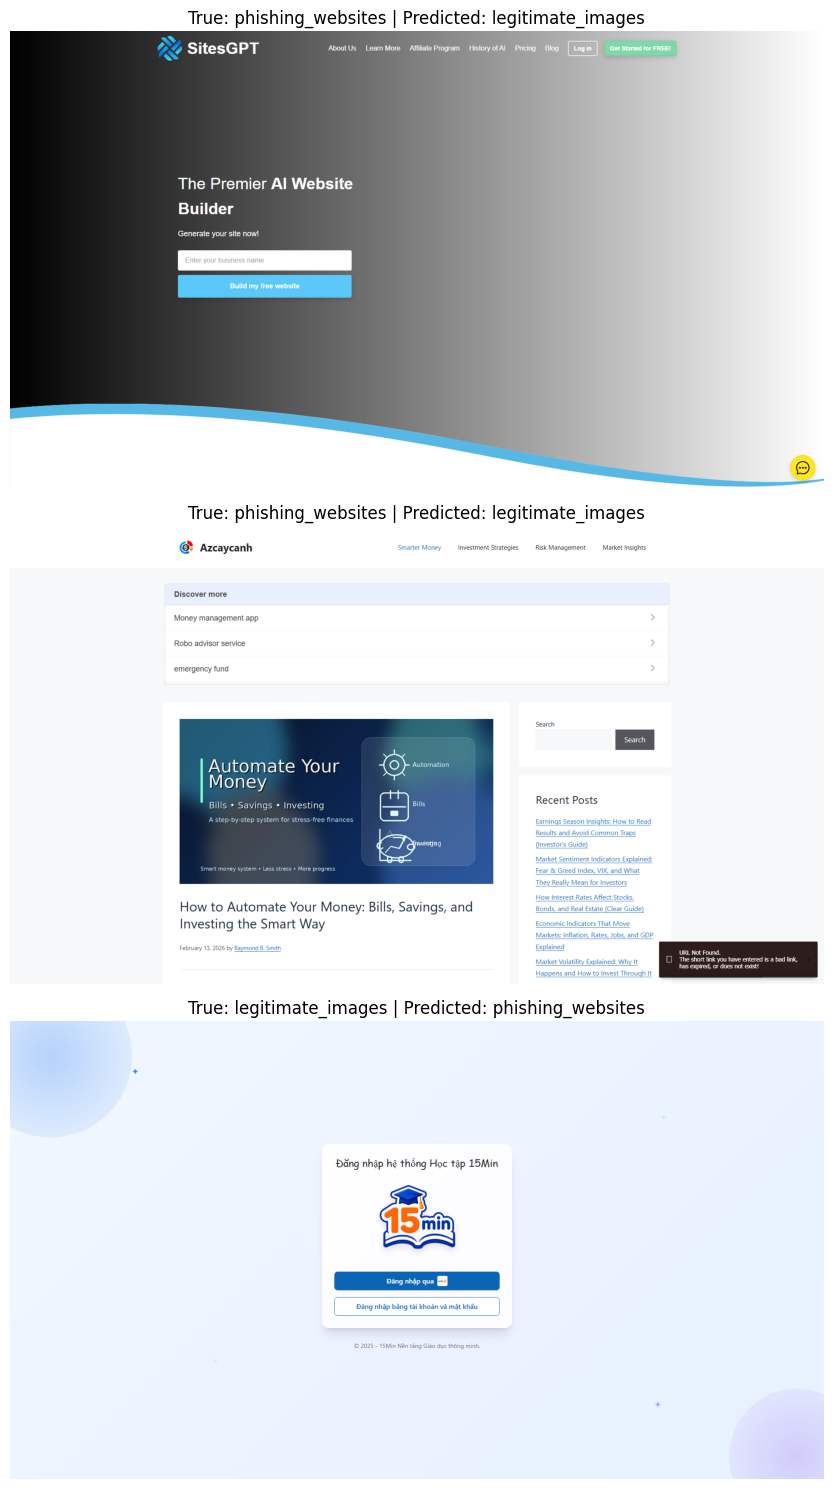

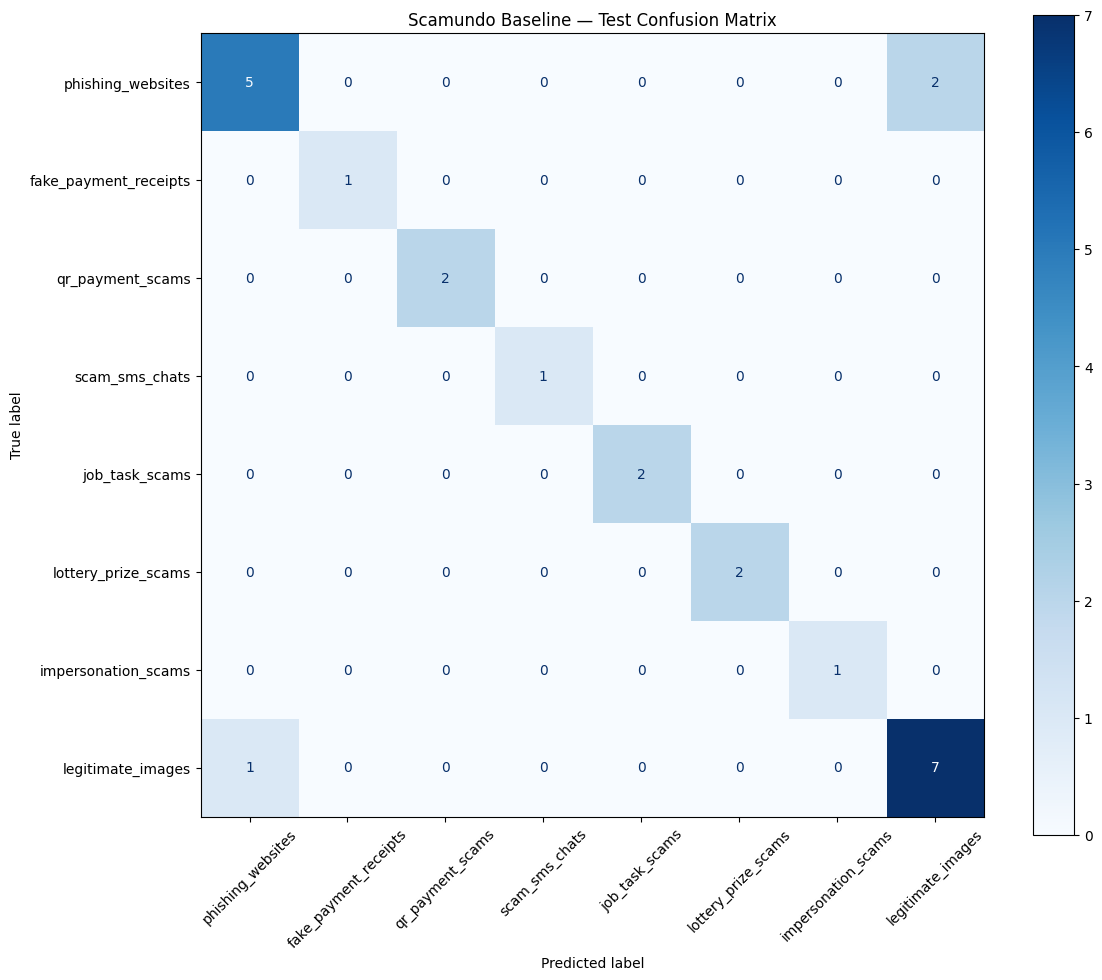

Error list and confusion matrix saved in reports/.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import joblib
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")
FEATURE_DIR = PROJECT_DIR / "reports" / "siglip_features"
MODEL_PATH = PROJECT_DIR / "models" / "siglip_logistic_classifier.joblib"

test = np.load(FEATURE_DIR / "test_features.npz")
X_test = test["X"]
y_test = test["y"]
paths = test["paths"]
classes = test["classes"].tolist()

clf = joblib.load(MODEL_PATH)
predictions = clf.predict(X_test)

# List incorrect predictions
wrong_indices = np.where(predictions != y_test)[0]

print(f"Test images: {len(y_test)}")
print(f"Correct: {(predictions == y_test).sum()}")
print(f"Incorrect: {len(wrong_indices)}")

error_rows = []
for i in wrong_indices:
    error_rows.append({
        "image_path": str(paths[i]),
        "true_label": classes[y_test[i]],
        "predicted_label": classes[predictions[i]]
    })

errors_df = pd.DataFrame(error_rows)
display(errors_df)

# Display misclassified images
if len(wrong_indices):
    fig, axes = plt.subplots(
        len(wrong_indices), 1,
        figsize=(12, 5 * len(wrong_indices))
    )
    if len(wrong_indices) == 1:
        axes = [axes]

    for ax, i in zip(axes, wrong_indices):
        try:
            image = Image.open(paths[i]).convert("RGB")
            ax.imshow(image)
            ax.set_title(
                f"True: {classes[y_test[i]]} | "
                f"Predicted: {classes[predictions[i]]}"
            )
            ax.axis("off")
        except Exception as e:
            ax.text(0.05, 0.5, f"Could not open image: {paths[i]}\n{e}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified test images in this run.")

# Confusion matrix: rows = true labels, columns = predicted labels
cm = confusion_matrix(
    y_test, predictions, labels=np.arange(len(classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title("Scamundo Baseline — Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Save results for your teammate
errors_df.to_csv(
    PROJECT_DIR / "reports" / "classifier_misclassified_images.csv",
    index=False
)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(
    PROJECT_DIR / "reports" / "classifier_test_confusion_matrix.csv"
)

print("Error list and confusion matrix saved in reports/.")


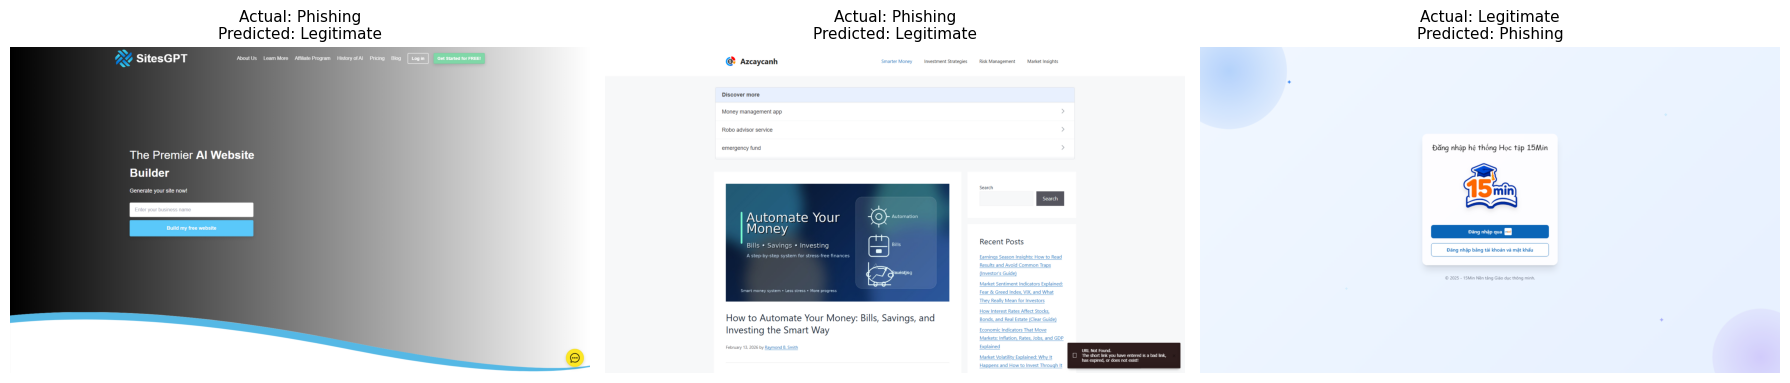

In [ ]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/Scamundo_Image_Module")

image_info = [
    (
        PROJECT_DIR / "splits/test/phishing_websites/phishing__ai_website_builder__homepage.png",
        "Actual: Phishing\nPredicted: Legitimate"
    ),
    (
        PROJECT_DIR / "splits/test/phishing_websites/phishing__azcaycanh__homepage.png",
        "Actual: Phishing\nPredicted: Legitimate"
    ),
    (
        PROJECT_DIR / "splits/test/legitimate_images/legitimate__15min__homepage.png",
        "Actual: Legitimate\nPredicted: Phishing"
    ),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (path, title) in zip(axes, image_info):
    if path.exists():
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_title(title, fontsize=11)
    else:
        ax.text(0.5, 0.5, f"Image not found:\n{path.name}",
                ha="center", va="center")
        ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total space: {total / 1e9:.2f} GB")
print(f"Used space:  {used / 1e9:.2f} GB")
print(f"Free space:  {free / 1e9:.2f} GB")

Total space: 120.94 GB
Used space:  46.90 GB
Free space:  74.02 GB


In [ ]:
!pip -q install -U huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.


In [ ]:
%pip install "huggingface-hub>=1.32.0,<2.0"

  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 2.2.0
    Uninstalling huggingface_hub-2.2.0:
      Successfully uninstalled huggingface_hub-2.2.0


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
from huggingface_hub import snapshot_download

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module"
)

DOWNLOAD_DIR = (
    PROJECT_DIR / "external_datasets" / "phishing_website_screenshots"
)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

snapshot_download(
    repo_id="shresthsamyak/phishing-website-screenshots",
    repo_type="dataset",
    local_dir=str(DOWNLOAD_DIR),
)

print("Dataset downloaded to:", DOWNLOAD_DIR)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8373 files:   0%|          | 0/8373 [00:00<?, ?it/s]

Dataset downloaded to: /content/drive/MyDrive/Scamundo_Image_Module/external_datasets/phishing_website_screenshots


In [ ]:
from pathlib import Path
from collections import Counter

DATASET_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module/"
    "external_datasets/phishing_website_screenshots"
)

files = [p for p in DATASET_DIR.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
for ext, count in Counter(
    p.suffix.lower() or "[no extension]" for p in files
).most_common():
    print(f"{ext}: {count}")

print("\nTop-level contents:")
for p in sorted(DATASET_DIR.iterdir()):
    if p.is_dir():
        print(f"[DIR]  {p.name}")
    else:
        print(f"[FILE] {p.name} ({p.stat().st_size / 1e6:.2f} MB)")

print("\nPossible label/metadata files:")
metadata_extensions = {".csv", ".json", ".jsonl", ".parquet", ".txt"}
for p in files:
    if p.suffix.lower() in metadata_extensions:
        print(p.relative_to(DATASET_DIR))

Total files: 25122

File types:
.lock: 8373
.metadata: 8373
.png: 8370
[no extension]: 2
.md: 1
.csv: 1
.tag: 1
.json: 1

Top-level contents:
[DIR]  .cache
[FILE] .gitattributes (0.00 MB)
[FILE] README.md (0.00 MB)
[DIR]  legitimate
[FILE] metadata.csv (2.84 MB)
[DIR]  phishing

Possible label/metadata files:
metadata.csv
.cache/huggingface/trees/757b719a5f348e393103ec0eee9f41f5bd26c0ad.json


In [ ]:
from PIL import Image
from collections import Counter

image_extensions = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp", ".gif"
}

image_paths = [
    p for p in files if p.suffix.lower() in image_extensions
]

print("Image files found:", len(image_paths))

dimensions = Counter()
unreadable = []

for p in image_paths:
    try:
        with Image.open(p) as img:
            dimensions[img.size] += 1
    except Exception:
        unreadable.append(str(p))

print("\nMost common image dimensions:")
for size, count in dimensions.most_common(10):
    print(f"{size}: {count}")

print("\nUnreadable images:", len(unreadable))
for p in unreadable[:10]:
    print(p)

Image files found: 8370

Most common image dimensions:
(1920, 1080): 8370

Unreadable images: 0


In [ ]:
from pathlib import Path
import pandas as pd

DATASET_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module/"
    "external_datasets/phishing_website_screenshots"
)

# 1. Count images in each class folder
for folder_name in ["phishing", "legitimate"]:
    folder = DATASET_DIR / folder_name
    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() == ".png"
    ]
    print(f"{folder_name}: {len(images)} images")

# 2. Inspect metadata
metadata_path = DATASET_DIR / "metadata.csv"
df = pd.read_csv(metadata_path)

print("\nMetadata shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 metadata rows:")
display(df.head(10))

print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing_count"))

phishing: 446 images
legitimate: 7924 images

Metadata shape: (8370, 25)

Column names:
['file_name', 'label', 'label_name', 'id', 'url', 'final_url', 'brand', 'brand_normalized', 'page_type', 'screenshot_type', 'title', 'timestamp', 'viewport_width', 'viewport_height', 'status_code', 'redirect_count', 'page_load_time_ms', 'file_size_bytes', 'image_width', 'image_height', 'image_hash', 'is_blank', 'is_captcha', 'is_error_page', 'source']

First 10 metadata rows:


,file_name,label,label_name,id,url,final_url,brand,brand_normalized,page_type,screenshot_type,...,redirect_count,page_load_time_ms,file_size_bytes,image_width,image_height,image_hash,is_blank,is_captcha,is_error_page,source
0,legitimate/111_wales_nhs_uk/homepage.png,0,legitimate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,legitimate/1177/homepage.png,0,legitimate,bb126493ec37c266,https://www.1177.se/hitta-vard/kontaktkort/Ske...,https://www.1177.se/hitta-vard/kontaktkort/Ske...,1177,1177,unknown,desktop,...,3.0,6850.0,125134.0,1920.0,1080.0,600338289696b6b2,False,False,False,csv
2,legitimate/1199seiu_funds/checkout.png,0,legitimate,5cfd0a655c52c886,https://www.1199seiubenefits.org/the-choice-is...,https://www.1199seiubenefits.org/the-choice-is...,1199SEIU Funds,1199seiu_funds,checkout,desktop,...,0.0,3070.0,709199.0,1920.0,1080.0,aa27010101200040,False,False,False,csv
3,legitimate/1199seiu_funds/dashboard.png,0,legitimate,97c0894029f87183,https://www.1199seiubenefits.org/home-care-wor...,https://www.1199seiubenefits.org/home-care-wor...,1199SEIU Funds,1199seiu_funds,dashboard,desktop,...,0.0,3762.0,606175.0,1920.0,1080.0,00c8c32327876367,False,False,False,csv
4,legitimate/1199seiu_funds/homepage.png,0,legitimate,11d41df519ad30e9,https://www.1199seiubenefits.org,https://www.1199seiubenefits.org/,1199SEIU Funds,1199seiu_funds,homepage,desktop,...,0.0,3411.0,1289239.0,1920.0,1080.0,328e4e45656e9a90,False,False,False,csv
5,legitimate/1199seiu_funds/signup.png,0,legitimate,fdefecd01d6cf358,https://www.1199seiubenefits.org/pension-couns...,https://www.1199seiubenefits.org/pension-couns...,1199SEIU Funds,1199seiu_funds,signup,desktop,...,0.0,2731.0,92289.0,1920.0,1080.0,736367636262666b,False,False,False,csv
6,legitimate/15min/homepage.png,0,legitimate,a3312c8cce805b83,http://english.bdu.edu.vn/content.php?i=8,https://15min-dev.hcmict.io/login?returnUrl=%2...,15Min,15min,login,desktop,...,2.0,3689.0,338774.0,1920.0,1080.0,cd9a4c4d6cacd46c,False,False,False,csv
7,legitimate/1cmerwzv/homepage.png,0,legitimate,779337d215593107,http://www.uob.edu.bh/english/,https://www.uob.edu.bh/wp-content/uploads/site...,1CMerWZV,1cmerwzv,unknown,desktop,...,3.0,4802.0,420843.0,1920.0,1080.0,000814e0c8580200,False,False,False,csv
8,legitimate/1xbet/homepage.png,0,legitimate,abad671c29d549c8,http://mchpolicy.org,https://oglerpets.com/,1xbet,1xbet,homepage,desktop,...,3.0,5579.0,274868.0,1920.0,1080.0,33338c0cd3c38f94,False,False,False,csv
9,legitimate/2006_07/homepage.png,0,legitimate,79163a583ef96e4d,http://www.bcbudget.gov.bc.ca/2006/sp/tsa/Mini...,https://www.bcbudget.gov.bc.ca/2006/sp/tsa/Min...,2006/07,2006_07,unknown,desktop,...,1.0,6991.0,139652.0,1920.0,1080.0,0d0c060616068e96,False,False,False,csv



Missing values per column:


,missing_count
file_name,0
label,0
label_name,0
id,905
url,905
final_url,905
brand,905
brand_normalized,909
page_type,905
screenshot_type,905


In [ ]:
readme_path = DATASET_DIR / "README.md"

print(readme_path.read_text(encoding="utf-8")[:10000])

---
license: other
task_categories:
- image-classification
tags:
- phishing
- cybersecurity
- website-screenshots
- security
pretty_name: Phishing Website Screenshots
size_categories:
- 1K<n<10K
---

# Phishing Website Screenshots

A dataset of **8,370 full-page website screenshots** labelled as **legitimate** or **phishing**, intended for training and evaluating visual phishing-detection models.

## Contents

| Label | `label` | Images |
|-------|:-------:|-------:|
| legitimate | 0 | 7,924 |
| phishing | 1 | 446 |
| **Total** | | **8,370** |

Screenshots were captured at a desktop viewport (1920×1080) as PNG images.

## Structure

```
legitimate/<brand>/<page>.png
phishing/<source>/<page>.png
metadata.csv
```

`metadata.csv` has one row per image. Key columns:

- `file_name` — path to the image (relative to the repo root)
- `label` — `0` = legitimate, `1` = phishing
- `label_name` — `legitimate` / `phishing`
- `url`, `final_url` — captured URL and post-redirect URL
- `brand`, `brand_

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module"
)

SOURCE_DIR = (
    PROJECT_DIR
    / "external_datasets"
    / "phishing_website_screenshots"
)

OUTPUT_DIR = PROJECT_DIR / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metadata = pd.read_csv(SOURCE_DIR / "metadata.csv")

# Keep only rows whose image paths exist.
metadata["full_path"] = metadata["file_name"].apply(
    lambda name: SOURCE_DIR / str(name)
)
metadata = metadata[metadata["full_path"].apply(Path.exists)].copy()

# Map the source labels to Scamundo's existing class names.
metadata["scamundo_label"] = metadata["label_name"].map({
    "phishing": "phishing_websites",
    "legitimate": "legitimate_images",
})

# Keep only the two expected classes.
metadata = metadata[
    metadata["scamundo_label"].notna()
].copy()

manifest_columns = [
    "file_name",
    "full_path",
    "label_name",
    "scamundo_label",
    "brand_normalized",
    "page_type",
    "image_hash",
    "url",
    "final_url",
]

manifest = metadata[manifest_columns].copy()

manifest_path = OUTPUT_DIR / "external_website_dataset_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Manifest saved:", manifest_path)
print("\nImage counts by source label:")
print(manifest["label_name"].value_counts(dropna=False))

print("\nImage counts by Scamundo label:")
print(manifest["scamundo_label"].value_counts(dropna=False))

print("\nMissing metadata fields:")
print(
    manifest[
        ["brand_normalized", "page_type", "image_hash", "url", "final_url"]
    ].isna().sum()
)

Manifest saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/external_website_dataset_manifest.csv

Image counts by source label:
label_name
legitimate    7924
phishing       446
Name: count, dtype: int64

Image counts by Scamundo label:
scamundo_label
legitimate_images    7924
phishing_websites     446
Name: count, dtype: int64

Missing metadata fields:
brand_normalized    909
page_type           905
image_hash          905
url                 905
final_url           905
dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module"
)

manifest_path = (
    PROJECT_DIR
    / "reports"
    / "external_website_dataset_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

hashes = manifest["image_hash"].dropna().astype(str)

print("Manifest rows:", len(manifest))
print("Rows with image hashes:", len(hashes))
print("Missing image hashes:", manifest["image_hash"].isna().sum())
print("Repeated hash rows:", hashes.duplicated().sum())

print("\nRepeated hashes:")
print(
    manifest[
        manifest["image_hash"].notna()
        & manifest["image_hash"].duplicated(keep=False)
    ][["file_name", "scamundo_label", "image_hash"]]
    .head(20)
)

Manifest rows: 8370
Rows with image hashes: 7465
Missing image hashes: 905
Repeated hash rows: 162

Repeated hashes:
                                             file_name     scamundo_label  \
51                        legitimate/about/payment.png  legitimate_images   
135       legitimate/administra_o_interna/homepage.png  legitimate_images   
146  legitimate/advancedgenomictechnology/homepage.png  legitimate_images   
209                  legitimate/air_liquide/signup.png  legitimate_images   
213  legitimate/air_liquide_in_the_united_kingdom/s...  legitimate_images   
251                      legitimate/alcon/homepage.png  legitimate_images   
252               legitimate/alcon_italia/homepage.png  legitimate_images   
360  legitimate/andover_war_memorial_hospital/signu...  legitimate_images   
465    legitimate/arizonaacademyofscience/homepage.png  legitimate_images   
484  legitimate/artsandhealthalliance_org/homepage.png  legitimate_images   
499           legitimate/ashtead_hos

In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module"
)

manifest_path = (
    PROJECT_DIR / "reports" / "external_website_dataset_manifest.csv"
)

df = pd.read_csv(manifest_path)

# Include all rows belonging to a repeated, non-missing hash group.
valid_hash = df["image_hash"].notna()

duplicates = df[
    valid_hash
    & df.loc[valid_hash, "image_hash"].duplicated(keep=False).reindex(
        df.index, fill_value=False
    )
].copy()

print("Rows in repeated-hash groups:", len(duplicates))
print("Repeated hash groups:", duplicates["image_hash"].nunique())

print("\nLargest repeated groups:")
group_sizes = (
    duplicates.groupby("image_hash")
    .agg(
        images=("file_name", "count"),
        labels=("scamundo_label", "nunique"),
        examples=("file_name", lambda s: " | ".join(s.head(4))),
    )
    .sort_values("images", ascending=False)
)

display(group_sizes.head(15))

duplicates.to_csv(
    PROJECT_DIR / "reports" / "external_repeated_hashes.csv",
    index=False,
)

print("\nSaved repeated-hash audit.")

Rows in repeated-hash groups: 250
Repeated hash groups: 88

Largest repeated groups:


,images,labels,examples
image_hash,,,
0000000000000000,11,2,legitimate/episcopal_high_school/login.png | l...
9c9ef8d2b3b36bc6,11,1,legitimate/ashtead_hospital/homepage.png | leg...
00000061144d6970,9,2,legitimate/www_aerostream_com/homepage.png | l...
0000000000081432,9,2,legitimate/artsandhealthalliance_org/homepage....
06000426060e4c06,6,1,phishing/artemius_lab/homepage.png | phishing/...
1313132d2d0d0191,4,1,legitimate/banner/payment.png | legitimate/ban...
0e061e0a2b1d03b0,4,1,legitimate/good_samaritan_hospital/payment.png...
222e703030723030,4,1,legitimate/bristol_dental_hospital/login.png |...
fffff3b3b3f3ffff,4,1,legitimate/ballyhoura_development_clg/login.pn...



Saved repeated-hash audit.


In [ ]:
from pathlib import Path
import hashlib
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module"
)

OLD_DIR = PROJECT_DIR / "splits"
NEW_DIR = PROJECT_DIR / "external_datasets" / "phishing_website_screenshots"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

image_exts = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}

old_images = [
    p for p in OLD_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_exts
]

new_images = [
    p for p in NEW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in image_exts
    and ".cache" not in p.parts
]

old_hashes = {}
for p in old_images:
    old_hashes.setdefault(sha256_file(p), []).append(str(p))

matches = []
for p in new_images:
    digest = sha256_file(p)
    if digest in old_hashes:
        for old_path in old_hashes[digest]:
            matches.append({
                "old_image": old_path,
                "new_image": str(p),
                "sha256": digest,
            })

matches_df = pd.DataFrame(matches)
print("Existing split images:", len(old_images))
print("External images checked:", len(new_images))
print("Exact cross-dataset matches:", len(matches_df))

if not matches_df.empty:
    display(matches_df.head(20))
    matches_df.to_csv(
        PROJECT_DIR / "reports" / "cross_dataset_exact_duplicates.csv",
        index=False,
    )

Existing split images: 160
External images checked: 8370
Exact cross-dataset matches: 111


,old_image,new_image,sha256
0,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,0fb00669b9f25dac01005a0df66340f2c34db17abdc793...
1,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,e2171105e2bff9106a8fbc021d6aded2b7e275624be8e5...
2,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,9b5085334981f27e464061504e1d04aa738ea67a714326...
3,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,bb80d6de99719c02b92e5e0a41baf0770df56adaa5651f...
4,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,87bfd3f117a3d502fcccb006a557457251fbc0c6c99c39...
5,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,4973024ed8988c9d6ff7eefe0f2fd9070a7ac597fb66ec...
6,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,7de5a69229dcf37008dd0687948c64cc6f0474730ba3ad...
7,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,12fd890d7341aab640180512f9fc1ed96be61b0966272e...
8,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,e5b4a2b6dbe927ede5fbd3b61a348864c3213c3a15bd75...
9,/content/drive/MyDrive/Scamundo_Image_Module/s...,/content/drive/MyDrive/Scamundo_Image_Module/e...,70178ec47cbd3a7921bfa65261b07d8714a19feb71e328...


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import hashlib
import os

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

RAW_DIR = ROOT / "raw"
SPLITS_DIR = ROOT / "splits"
EXTERNAL_DIR = ROOT / "external_datasets/phishing_website_screenshots"
REPORTS_DIR = ROOT / "reports"
MODELS_DIR = ROOT / "models"

EXTERNAL_MANIFEST = REPORTS_DIR / "external_website_dataset_manifest.csv"
DUPLICATES_FILE = REPORTS_DIR / "cross_dataset_exact_duplicates.csv"

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

print("Project folder exists:", ROOT.exists())
print("External dataset exists:", EXTERNAL_DIR.exists())
print("External manifest exists:", EXTERNAL_MANIFEST.exists())
print("Duplicate report exists:", DUPLICATES_FILE.exists())


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

print("Drive connected:", Path("/content/drive/MyDrive").exists())
print("Scamundo folder exists:", ROOT.exists())

Drive connected: True
Scamundo folder exists: True


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RAW_DIR = ROOT / "raw"
SPLITS_DIR = ROOT / "splits"

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
old_records = []

# Check whether the original raw folders contain all 8 categories
raw_has_all_classes = all(
    (RAW_DIR / c).exists() for c in CLASSES
)

if raw_has_all_classes:
    for cls in CLASSES:
        for p in (RAW_DIR / cls).rglob("*"):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
                old_records.append({
                    "path": str(p),
                    "class_name": cls,
                })
else:
    # Otherwise, collect images from the existing splits
    for split in ["train", "val", "test"]:
        for cls in CLASSES:
            folder = SPLITS_DIR / split / cls
            if folder.exists():
                for p in folder.rglob("*"):
                    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
                        old_records.append({
                            "path": str(p),
                            "class_name": cls,
                        })

old_df = pd.DataFrame(old_records)

if old_df.empty:
    raise ValueError("No images found. Check your raw and splits folders.")

old_df = old_df.drop_duplicates(subset=["path"]).reset_index(drop=True)

print("Original unique image paths:", len(old_df))
print("\nImages per category:")
print(old_df["class_name"].value_counts().reindex(CLASSES, fill_value=0))

missing = sum(not Path(p).is_file() for p in old_df["path"])
print("\nMissing files:", missing)


Original unique image paths: 160

Images per category:
class_name
phishing_websites        50
fake_payment_receipts    10
qr_payment_scams         10
scam_sms_chats           10
job_task_scams           10
lottery_prize_scams      10
impersonation_scams      10
legitimate_images        50
Name: count, dtype: int64

Missing files: 0


In [ ]:

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"

EXTERNAL_MANIFEST = REPORTS_DIR / "external_website_dataset_manifest.csv"
DUPLICATES_FILE = REPORTS_DIR / "cross_dataset_exact_duplicates.csv"

# Check that the required files exist
print("External manifest exists:", EXTERNAL_MANIFEST.exists())
print("Duplicate report exists:", DUPLICATES_FILE.exists())

if not EXTERNAL_MANIFEST.exists():
    raise FileNotFoundError(
        f"Could not find: {EXTERNAL_MANIFEST}"
    )

# Load the new dataset manifest
ext_df = pd.read_csv(EXTERNAL_MANIFEST)

print("\nExternal dataset rows:", len(ext_df))
print("\nAvailable columns:")
print(ext_df.columns.tolist())

print("\nLabels in the new dataset:")
print(ext_df["label_name"].value_counts(dropna=False))

# Load the exact-duplicate report
if DUPLICATES_FILE.exists():
    dup_df = pd.read_csv(DUPLICATES_FILE)
    print("\nExact cross-dataset duplicate matches:", len(dup_df))
else:
    dup_df = pd.DataFrame()
    print("\nWARNING: Exact-duplicate report not found.")


External manifest exists: True
Duplicate report exists: True

External dataset rows: 8370

Available columns:
['file_name', 'full_path', 'label_name', 'scamundo_label', 'brand_normalized', 'page_type', 'image_hash', 'url', 'final_url']

Labels in the new dataset:
label_name
legitimate    7924
phishing       446
Name: count, dtype: int64

Exact cross-dataset duplicate matches: 111


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"

# The original dataset from Step 2
# old_df must already exist in your notebook.

EXTERNAL_MANIFEST = REPORTS_DIR / "external_website_dataset_manifest.csv"
DUPLICATES_FILE = REPORTS_DIR / "cross_dataset_exact_duplicates.csv"

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

# Load the new dataset and duplicate report
ext_df = pd.read_csv(EXTERNAL_MANIFEST)
dup_df = pd.read_csv(DUPLICATES_FILE)

# Map the external labels to existing Scamundo categories
label_map = {
    "phishing": "phishing_websites",
    "legitimate": "legitimate_images",
}

ext_df["class_name"] = ext_df["label_name"].map(label_map)

if ext_df["class_name"].isna().any():
    raise ValueError("Some external labels could not be mapped.")

# Keep only images whose files exist
ext_df = ext_df[
    ext_df["full_path"].map(lambda p: Path(str(p)).is_file())
].copy()

# Normalize paths for reliable duplicate matching
ext_df["path"] = ext_df["full_path"].map(
    lambda p: str(Path(str(p)).resolve())
)

if "new_image" not in dup_df.columns:
    raise ValueError("The duplicate report has no 'new_image' column.")

duplicate_paths = set(
    dup_df["new_image"].dropna().map(
        lambda p: str(Path(str(p)).resolve())
    )
)

before = len(ext_df)

# Keep the original images and remove matching copies from the new dataset
ext_df = ext_df[
    ~ext_df["path"].isin(duplicate_paths)
].copy()

print("External images before duplicate removal:", before)
print("External images removed:", before - len(ext_df))
print("External images retained:", len(ext_df))

# Prepare original records
original_df = old_df[["path", "class_name"]].copy()
original_df["path"] = original_df["path"].map(
    lambda p: str(Path(str(p)).resolve())
)
original_df["source"] = "original"

# Prepare external records
external_df = ext_df[["path", "class_name"]].copy()
external_df["source"] = "external"

# Combine all eight categories
combined_df = pd.concat(
    [original_df, external_df],
    ignore_index=True
)

# Ensure no file path is included twice
combined_df = combined_df.drop_duplicates(
    subset=["path"]
).reset_index(drop=True)

# Validate the combined dataset
assert combined_df["class_name"].isin(CLASSES).all()
assert combined_df["path"].is_unique

missing_paths = combined_df.loc[
    ~combined_df["path"].map(lambda p: Path(p).is_file()),
    "path"
]

if not missing_paths.empty:
    raise FileNotFoundError(
        f"{len(missing_paths)} image files are missing."
    )

# Save a new manifest without changing existing data or models
output_path = REPORTS_DIR / "combined_8class_dataset_manifest.csv"
combined_df.to_csv(output_path, index=False)

print("\nTOTAL COMBINED IMAGES:", len(combined_df))
print("\nImages per category:")
print(
    combined_df["class_name"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
)

print("\nImages by source:")
print(combined_df["source"].value_counts())

print("\nManifest saved to:", output_path)


External images before duplicate removal: 8370
External images removed: 111
External images retained: 8259

TOTAL COMBINED IMAGES: 8419

Images per category:
class_name
phishing_websites         436
fake_payment_receipts      10
qr_payment_scams           10
scam_sms_chats             10
job_task_scams             10
lottery_prize_scams        10
impersonation_scams        10
legitimate_images        7923
Name: count, dtype: int64

Images by source:
source
external    8259
original     160
Name: count, dtype: int64

Manifest saved to: /content/drive/MyDrive/Scamundo_Image_Module/reports/combined_8class_dataset_manifest.csv


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"

manifest_path = REPORTS_DIR / "combined_8class_dataset_manifest.csv"
df = pd.read_csv(manifest_path)

# Load external metadata to identify related website screenshots
external_meta = pd.read_csv(
    REPORTS_DIR / "external_website_dataset_manifest.csv"
)

# Map external labels to Scamundo's eight categories
label_map = {
    "phishing": "phishing_websites",
    "legitimate": "legitimate_images",
}
external_meta["class_name"] = external_meta["label_name"].map(label_map)

# Create grouping IDs so screenshots from the same site/brand
# can be kept together during splitting.
meta_lookup = {}

for _, row in external_meta.iterrows():
    path = str(Path(row["full_path"]).resolve())
    brand = str(row.get("brand_normalized", "")).strip()
    url = str(row.get("final_url", "")).strip()
    source_label = str(row.get("label_name", "")).strip()

    if brand and brand.lower() not in {"nan", "none", ""}:
        group_value = f"brand:{brand.lower()}"
    elif url and url.lower() not in {"nan", "none", ""}:
        from urllib.parse import urlparse
        group_value = f"url:{urlparse(url).netloc.lower()}"
    else:
        # Fallback to the source folder, if metadata is unavailable
        p = Path(row["full_path"])
        group_value = f"folder:{p.parent.name.lower()}"

    meta_lookup[path] = f"external_{source_label}_{group_value}"

def get_group(row):
    path = str(Path(row["path"]).resolve())

    if row["source"] == "external":
        return meta_lookup.get(path, f"external_fallback_{Path(path).stem}")

    # Keep each original image as its own group for now.
    # We will check image duplicates separately if needed.
    return f"original_{Path(path).name}"

df["group_id"] = df.apply(get_group, axis=1)

print("Images:", len(df))
print("Unique groups:", df["group_id"].nunique())
print("\nClass counts:")
print(df["class_name"].value_counts())

print("\nGroups per class:")
print(df.groupby("class_name")["group_id"].nunique())


Images: 8419
Unique groups: 6486

Class counts:
class_name
legitimate_images        7923
phishing_websites         436
qr_payment_scams           10
fake_payment_receipts      10
scam_sms_chats             10
job_task_scams             10
lottery_prize_scams        10
impersonation_scams        10
Name: count, dtype: int64

Groups per class:
class_name
fake_payment_receipts      10
impersonation_scams        10
job_task_scams             10
legitimate_images        6029
lottery_prize_scams        10
phishing_websites         397
qr_payment_scams           10
scam_sms_chats             10
Name: group_id, dtype: int64


In [ ]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"

df = pd.read_csv(REPORTS_DIR / "combined_8class_dataset_manifest.csv")

# Recreate the same groups as in Step 5
external_meta = pd.read_csv(
    REPORTS_DIR / "external_website_dataset_manifest.csv"
)

label_map = {
    "phishing": "phishing_websites",
    "legitimate": "legitimate_images",
}
external_meta["class_name"] = external_meta["label_name"].map(label_map)

from urllib.parse import urlparse

meta_lookup = {}

for _, row in external_meta.iterrows():
    path = str(Path(row["full_path"]).resolve())
    brand = str(row.get("brand_normalized", "")).strip()
    url = str(row.get("final_url", "")).strip()
    source_label = str(row.get("label_name", "")).strip()

    if brand and brand.lower() not in {"nan", "none", ""}:
        group_value = f"brand:{brand.lower()}"
    elif url and url.lower() not in {"nan", "none", ""}:
        group_value = f"url:{urlparse(url).netloc.lower()}"
    else:
        group_value = f"folder:{Path(row['full_path']).parent.name.lower()}"

    meta_lookup[path] = f"external_{source_label}_{group_value}"

def get_group(row):
    path = str(Path(row["path"]).resolve())
    if row["source"] == "external":
        return meta_lookup.get(path, f"external_fallback_{Path(path).stem}")
    return f"original_{Path(path).name}"

df["group_id"] = df.apply(get_group, axis=1)

# First reserve approximately 15% for testing.
outer_splitter = StratifiedGroupKFold(
    n_splits=7, shuffle=True, random_state=42
)

trainval_idx, test_idx = next(
    outer_splitter.split(df, df["class_name"], groups=df["group_id"])
)

trainval_df = df.iloc[trainval_idx].copy()
test_df = df.iloc[test_idx].copy()

# Then reserve approximately 15% of the full dataset for validation.
inner_splitter = StratifiedGroupKFold(
    n_splits=6, shuffle=True, random_state=43
)

train_idx, val_idx = next(
    inner_splitter.split(
        trainval_df,
        trainval_df["class_name"],
        groups=trainval_df["group_id"],
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Verify there is no group overlap between splits.
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Save new split manifests separately.
split_dir = REPORTS_DIR / "combined_8class_splits"
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train.csv", index=False)
val_df.to_csv(split_dir / "val.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

print("Split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTraining class counts:")
print(train_df["class_name"].value_counts().sort_index())

print("\nValidation class counts:")
print(val_df["class_name"].value_counts().sort_index())

print("\nTest class counts:")
print(test_df["class_name"].value_counts().sort_index())

print("\nGroup overlap:", len(train_groups & val_groups),
      len(train_groups & test_groups),
      len(val_groups & test_groups))

print("\nSplit manifests saved in:", split_dir)


Split sizes:
Train: 6024
Validation: 1212
Test: 1183

Training class counts:
class_name
fake_payment_receipts       7
impersonation_scams         8
job_task_scams              7
legitimate_images        5669
lottery_prize_scams         6
phishing_websites         311
qr_payment_scams            8
scam_sms_chats              8
Name: count, dtype: int64

Validation class counts:
class_name
fake_payment_receipts       1
impersonation_scams         1
job_task_scams              2
legitimate_images        1144
lottery_prize_scams         2
phishing_websites          60
qr_payment_scams            1
scam_sms_chats              1
Name: count, dtype: int64

Test class counts:
class_name
fake_payment_receipts       2
impersonation_scams         1
job_task_scams              1
legitimate_images        1110
lottery_prize_scams         2
phishing_websites          65
qr_payment_scams            1
scam_sms_chats              1
Name: count, dtype: int64

Group overlap: 0 0 0

Split manifests saved i

In [ ]:

!pip -q install transformers scikit-learn joblib pillow


In [ ]:

import torch
import transformers
import sklearn
import joblib
from PIL import Image

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())
print("\nAll required libraries imported successfully!")


PyTorch: 2.11.0+cu130
Transformers: 5.20.1
Scikit-learn: 1.6.1
GPU available: True

All required libraries imported successfully!


In [ ]:

import torch
from transformers import AutoProcessor, AutoModel
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"
SPLIT_DIR = REPORTS_DIR / "combined_8class_splits"

MODEL_NAME = "google/siglip-base-patch16-224"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

processor = AutoProcessor.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device)
encoder.eval()

print("SigLIP loaded successfully!")
print("Model device:", next(encoder.parameters()).device)


Device: cuda


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

SigLIP loaded successfully!
Model device: cuda:0


In [ ]:

import pandas as pd
import numpy as np
import torch
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"
SPLIT_DIR = REPORTS_DIR / "combined_8class_splits"
FEATURE_DIR = REPORTS_DIR / "combined_8class_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

class ImageDataset(Dataset):
    def __init__(self, csv_path):
        self.df = pd.read_csv(csv_path)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            image = Image.open(row["path"]).convert("RGB")
        except Exception as e:
            raise RuntimeError(f"Could not read image: {row['path']}") from e

        pixel_values = processor(
            images=image, return_tensors="pt"
        )["pixel_values"].squeeze(0)

        return pixel_values, row["class_name"], row["path"]

def extract_features(split_name, batch_size=32):
    csv_path = SPLIT_DIR / f"{split_name}.csv"
    dataset = ImageDataset(csv_path)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
    )

    features = []
    labels = []
    paths = []

    with torch.inference_mode():
        for batch_idx, (pixels, batch_labels, batch_paths) in enumerate(loader):
            pixels = pixels.to(device)

            outputs = encoder.get_image_features(pixel_values=pixels)

            if hasattr(outputs, "pooler_output"):
                outputs = outputs.pooler_output
            elif hasattr(outputs, "last_hidden_state"):
                outputs = outputs.last_hidden_state

            if outputs.ndim == 3:
                outputs = outputs[:, 0, :]

            outputs = torch.nn.functional.normalize(
                outputs.float(), p=2, dim=-1
            )

            features.append(outputs.cpu().numpy())
            labels.extend(batch_labels)
            paths.extend(batch_paths)

            if (batch_idx + 1) % 20 == 0:
                print(
                    f"{split_name}: "
                    f"{min((batch_idx + 1) * batch_size, len(dataset))}"
                    f"/{len(dataset)} images processed"
                )

    X = np.concatenate(features, axis=0)
    y = np.array([CLASSES.index(label) for label in labels])

    output_path = FEATURE_DIR / f"{split_name}_features.npz"
    np.savez_compressed(
        output_path,
        X=X,
        y=y,
        paths=np.array(paths),
        classes=np.array(CLASSES),
    )

    print(f"\n{split_name} features shape: {X.shape}")
    print(f"{split_name} labels shape: {y.shape}")
    print("Saved:", output_path)

for split_name in ["train", "val", "test"]:
    extract_features(split_name)

print("\nAll three splits processed successfully!")


train: 640/6024 images processed
train: 1280/6024 images processed
train: 1920/6024 images processed
train: 2560/6024 images processed
train: 3200/6024 images processed
train: 3840/6024 images processed
train: 4480/6024 images processed
train: 5120/6024 images processed
train: 5760/6024 images processed

train features shape: (6024, 768)
train labels shape: (6024,)
Saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/combined_8class_features/train_features.npz
val: 640/1212 images processed

val features shape: (1212, 768)
val labels shape: (1212,)
Saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/combined_8class_features/val_features.npz
test: 640/1183 images processed

test features shape: (1183, 768)
test labels shape: (1183,)
Saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/combined_8class_features/test_features.npz

All three splits processed successfully!


In [ ]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"
FEATURE_DIR = REPORTS_DIR / "combined_8class_features"
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]

# Load the saved feature vectors
train_data = np.load(FEATURE_DIR / "train_features.npz")
val_data = np.load(FEATURE_DIR / "val_features.npz")
test_data = np.load(FEATURE_DIR / "test_features.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_val, y_val = val_data["X"], val_data["y"]
X_test, y_test = test_data["X"], test_data["y"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

# Train a balanced eight-class classifier
classifier = LogisticRegression(
    C=0.1,
    class_weight="balanced",
    max_iter=2000,
    random_state=42,
)

classifier.fit(X_train, y_train)

# Evaluate on validation data to check performance before final testing
val_pred = classifier.predict(X_val)

print("\nVALIDATION RESULTS")
print("Accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))
print("Macro F1:", round(f1_score(
    y_val, val_pred, average="macro", zero_division=0
), 4))

print("\nValidation classification report:")
print(classification_report(
    y_val,
    val_pred,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    zero_division=0,
))

# Save this model under a new filename; do not overwrite the original.
model_path = MODELS_DIR / "siglip_logistic_classifier_8class_expanded.joblib"

joblib.dump(
    {
        "classifier": classifier,
        "classes": CLASSES,
        "model_name": "google/siglip-base-patch16-224",
        "feature_dim": X_train.shape[1],
    },
    model_path,
)

print("\nNew eight-class model saved to:")
print(model_path)
print("\nOriginal model has not been overwritten.")


Training features: (6024, 768)
Validation features: (1212, 768)
Test features: (1183, 768)

VALIDATION RESULTS
Accuracy: 0.8639
Balanced accuracy: 0.9622
Macro F1: 0.8711

Validation classification report:
                       precision    recall  f1-score   support

    phishing_websites       0.25      0.83      0.38        60
fake_payment_receipts       1.00      1.00      1.00         1
     qr_payment_scams       1.00      1.00      1.00         1
       scam_sms_chats       1.00      1.00      1.00         1
       job_task_scams       1.00      1.00      1.00         2
  lottery_prize_scams       1.00      1.00      1.00         2
  impersonation_scams       0.50      1.00      0.67         1
    legitimate_images       0.99      0.86      0.92      1144

             accuracy                           0.86      1212
            macro avg       0.84      0.96      0.87      1212
         weighted avg       0.95      0.86      0.90      1212


New eight-class model saved to:
/c

In [ ]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"
FEATURE_DIR = REPORTS_DIR / "combined_8class_features"
MODELS_DIR = ROOT / "models"

model_path = MODELS_DIR / "siglip_logistic_classifier_8class_expanded.joblib"
test_path = FEATURE_DIR / "test_features.npz"

saved = joblib.load(model_path)
classifier = saved["classifier"]
CLASSES = saved["classes"]

test_data = np.load(test_path)
X_test = test_data["X"]
y_test = test_data["y"]

# Evaluate the held-out test set
test_pred = classifier.predict(X_test)

print("TEST RESULTS")
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, test_pred), 4
))
print("Macro F1:", round(
    f1_score(y_test, test_pred, average="macro", zero_division=0), 4
))

print("\nClassification report:")
report = classification_report(
    y_test,
    test_pred,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    zero_division=0,
    output_dict=True,
)
print(pd.DataFrame(report).T.round(4))

# Save the test classification report and confusion matrix
report_df = pd.DataFrame(report).T
report_df.to_csv(REPORTS_DIR / "expanded_8class_test_report.csv")

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=list(range(len(CLASSES))),
)
cm_df = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
cm_df.to_csv(REPORTS_DIR / "expanded_8class_test_confusion_matrix.csv")

print("\nReports saved in:", REPORTS_DIR)


TEST RESULTS
Accuracy: 0.8859
Balanced accuracy: 0.954
Macro F1: 0.919

Classification report:
                       precision  recall  f1-score    support
phishing_websites         0.2892  0.7385    0.4156    65.0000
fake_payment_receipts     1.0000  1.0000    1.0000     2.0000
qr_payment_scams          1.0000  1.0000    1.0000     1.0000
scam_sms_chats            1.0000  1.0000    1.0000     1.0000
job_task_scams            1.0000  1.0000    1.0000     1.0000
lottery_prize_scams       1.0000  1.0000    1.0000     2.0000
impersonation_scams       1.0000  1.0000    1.0000     1.0000
legitimate_images         0.9832  0.8937    0.9363  1110.0000
accuracy                  0.8859  0.8859    0.8859     0.8859
macro avg                 0.9090  0.9540    0.9190  1183.0000
weighted avg              0.9451  0.8859    0.9081  1183.0000

Reports saved in: /content/drive/MyDrive/Scamundo_Image_Module/reports


In [ ]:

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
REPORTS_DIR = ROOT / "reports"

cm_path = REPORTS_DIR / "expanded_8class_test_confusion_matrix.csv"
cm = pd.read_csv(cm_path, index_col=0)

print("Confusion matrix:")
print(cm)

print("\nActual phishing images classified as other categories:")
print(cm.loc["phishing_websites"].drop("phishing_websites").sort_values(
    ascending=False
))

print("\nOther categories incorrectly classified as phishing:")
print(cm["phishing_websites"].drop("phishing_websites").sort_values(
    ascending=False
))


Confusion matrix:
                       phishing_websites  fake_payment_receipts  \
phishing_websites                     48                      0   
fake_payment_receipts                  0                      2   
qr_payment_scams                       0                      0   
scam_sms_chats                         0                      0   
job_task_scams                         0                      0   
lottery_prize_scams                    0                      0   
impersonation_scams                    0                      0   
legitimate_images                    118                      0   

                       qr_payment_scams  scam_sms_chats  job_task_scams  \
phishing_websites                     0               0               0   
fake_payment_receipts                 0               0               0   
qr_payment_scams                      1               0               0   
scam_sms_chats                        0               1               0   
job

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

# Separate workspace for the new payment-receipt images
DATA_DIR = ROOT / "raw" / "fake_payment_receipts_public"

folders = [
    DATA_DIR / "incoming",
    DATA_DIR / "verified_fake",
    DATA_DIR / "verified_genuine",
    DATA_DIR / "needs_review",
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

print("New data workspace ready:")
for folder in folders:
    print(f"  {folder}")

print("\nExisting models preserved:")
for model_path in [
    ROOT / "models" / "siglip_logistic_classifier.joblib",
    ROOT / "models" / "siglip_logistic_classifier_8class_expanded.joblib",
]:
    print(f"  {model_path.name}: {'FOUND' if model_path.exists() else 'NOT FOUND'}")

print("\nNo existing images or models were modified.")

New data workspace ready:
  /content/drive/MyDrive/Scamundo_Image_Module/raw/fake_payment_receipts_public/incoming
  /content/drive/MyDrive/Scamundo_Image_Module/raw/fake_payment_receipts_public/verified_fake
  /content/drive/MyDrive/Scamundo_Image_Module/raw/fake_payment_receipts_public/verified_genuine
  /content/drive/MyDrive/Scamundo_Image_Module/raw/fake_payment_receipts_public/needs_review

Existing models preserved:
  siglip_logistic_classifier.joblib: FOUND
  siglip_logistic_classifier_8class_expanded.joblib: FOUND

No existing images or models were modified.


In [ ]:
import requests
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
RESEARCH_DIR = ROOT / "raw" / "fake_payment_receipts_public" / "research_sources"
RESEARCH_DIR.mkdir(parents=True, exist_ok=True)

repo = "DeathKnell837/ForgeGuard"
headers = {"Accept": "application/vnd.github+json"}

# Inspect repository metadata
r = requests.get(
    f"https://api.github.com/repos/{repo}",
    headers=headers,
    timeout=30
)
print("Repository API status:", r.status_code)

if r.status_code != 200:
    print(r.text[:1000])
else:
    info = r.json()
    print("Repository:", info.get("html_url"))
    print("Description:", info.get("description"))
    print("Default branch:", info.get("default_branch"))
    print("License reported by GitHub:", (info.get("license") or {}).get("spdx_id"))

    # List repository files
    branch = info["default_branch"]
    tree_response = requests.get(
        f"https://api.github.com/repos/{repo}/git/trees/{branch}?recursive=1",
        headers=headers,
        timeout=60
    )
    print("\nFile listing status:", tree_response.status_code)

    if tree_response.status_code == 200:
        files = tree_response.json().get("tree", [])
        for item in files:
            if item.get("type") == "blob":
                print(item["path"], f"({item.get('size', 0):,} bytes)")

    # Read README without executing anything
    readme_response = requests.get(
        f"https://api.github.com/repos/{repo}/readme",
        headers=headers,
        timeout=30
    )
    if readme_response.status_code == 200:
        readme_data = readme_response.json()
        readme = requests.get(readme_data["download_url"], timeout=30)
        if readme.status_code == 200:
            readme_path = RESEARCH_DIR / "ForgeGuard_README.md"
            readme_path.write_text(readme.text, encoding="utf-8")
            print("\nREADME saved to:", readme_path)
            print("\nREADME preview:\n")
            print(readme.text[:10000])
        else:
            print("Could not retrieve README text.")

Repository API status: 200
Repository: https://github.com/DeathKnell837/ForgeGuard
Description: ForgeGuard — CNN-based Digital Receipt Forgery Detection System. BSCS Thesis: "Securing Mobile Transaction: A Comparative Evaluation of CNN Architectures in Detecting Digital Receipt Forgery" (NDMC, 2026)
Default branch: main
License reported by GitHub: None

File listing status: 200
.agents/AGENTS.md (10,412 bytes)
.devcontainer/devcontainer.json (1,028 bytes)
.gitignore (2,759 bytes)
.streamlit/config.toml (140 bytes)
01_System_Prototype/.streamlit/config.toml (203 bytes)
01_System_Prototype/README.md (7,064 bytes)
01_System_Prototype/database/benchmark_records_log.json (16,824 bytes)
01_System_Prototype/models/benchmark_records_log.json (16,824 bytes)
01_System_Prototype/models/evaluation_metrics.json (22,922 bytes)
01_System_Prototype/models/pure_empirical_benchmark.json (1,050 bytes)
01_System_Prototype/requirements.txt (104 bytes)
01_System_Prototype/run_system.bat (890 bytes)
01_Syste

In [ ]:
from pathlib import Path
import requests

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
README_PATH = (
    ROOT / "raw" / "fake_payment_receipts_public"
    / "research_sources" / "ForgeGuard_README.md"
)

readme = README_PATH.read_text(encoding="utf-8", errors="replace")

# Show relevant README sections
keywords = [
    "Empirical Dataset Specifications",
    "Dataset",
    "Data Source",
    "License",
    "Academic Research",
    "Redistribution",
    "Download",
]

print("README:", README_PATH)
print("README exists:", README_PATH.exists())

for keyword in keywords:
    matches = [
        i for i, line in enumerate(readme.splitlines())
        if keyword.lower() in line.lower()
    ]
    print(f"\n--- {keyword}: {len(matches)} match(es) ---")
    lines = readme.splitlines()
    for i in matches[:2]:
        start = max(0, i - 2)
        end = min(len(lines), i + 8)
        print("\n".join(lines[start:end]))
        print()

# Check common license filenames through GitHub's API
repo = "DeathKnell837/ForgeGuard"
api = f"https://api.github.com/repos/{repo}/contents/"
response = requests.get(api, timeout=30)

print("\nRepository root license check:")
if response.ok:
    names = {item["name"].lower() for item in response.json()}
    print("LICENSE present:", any(
        name in names for name in ["license", "license.md", "license.txt", "license.rst"]
    ))
    print("Root files:", sorted(names))
else:
    print("Could not check repository root:", response.status_code)

README: /content/drive/MyDrive/Scamundo_Image_Module/raw/fake_payment_receipts_public/research_sources/ForgeGuard_README.md
README exists: True

--- Empirical Dataset Specifications: 1 match(es) ---
---

## Empirical Dataset Specifications

The benchmark dataset consists of a 1:1 balanced distribution of 1,000 base downloadable GCash transaction receipts (and their paired 1,000 Messenger-compressed versions):

```
Empirical Evaluation Dataset (N = 1,000 Base Receipts)
├── Experimental Partition (N = 900 Images)
│   ├── Authentic Receipts (450 Images, 50.0%)


--- Dataset: 7 match(es) ---
**Receipt or Deceit: A Cross-Architecture Analysis of Convolutional Neural Network Models in Detecting Forged Digital Transaction Receipts**

[Live Web Demo](https://forgeguard.streamlit.app/) &bull; [System Architecture](#system-architecture) &bull; [Empirical Benchmark](#empirical-benchmark-evaluation) &bull; [Dataset](#empirical-dataset-specifications) &bull; [Installation](#quickstart--local-deploy

In [ ]:

import requests

REPO = "DeathKnell837/ForgeGuard"
API = f"https://api.github.com/repos/{REPO}/git/trees/main?recursive=1"

response = requests.get(
    API,
    params={"x": "1"},
    timeout=60
)

print("GitHub API status:", response.status_code)

if response.ok:
    tree = response.json().get("tree", [])

    print("Total repository entries:", len(tree))

    keywords = [
        "dataset", "data/", "authentic", "forged",
        "genuine", "fake", "receipt", "train",
        "test", "validation", "license"
    ]

    print("\nPotentially relevant paths:\n")

    matches = []
    for item in tree:
        path = item.get("path", "")
        low = path.lower()

        if any(keyword in low for keyword in keywords):
            matches.append(
                (path, item.get("type"), item.get("size"))
            )

    for path, item_type, size in matches[:150]:
        size_text = f"{size:,} bytes" if size is not None else "size unknown"
        print(f"{item_type:5} | {size_text:>15} | {path}")

    if len(matches) > 150:
        print(f"\nShowing first 150 of {len(matches)} matches.")
else:
    print(response.text[:1000])


GitHub API status: 200
Total repository entries: 2257

Potentially relevant paths:

blob  |   466,086 bytes | 01_System_Prototype/screenshots/02_authentic_receipt_analysis.png
blob  |   493,737 bytes | 01_System_Prototype/screenshots/03_forged_edited_receipt_analysis.png
blob  |   202,816 bytes | 01_System_Prototype/screenshots/07_empirical_dataset_composition.png
blob  |   150,130 bytes | 01_System_Prototype/src/assets/lottie_stickers/07_receipt_scan.json
blob  |    86,664 bytes | 01_System_Prototype/src/samples/authentic.jpg
tree  |    size unknown | 01_System_Prototype/src/training
blob  |    16,644 bytes | 01_System_Prototype/src/training/train.py
blob  |   123,749 bytes | ai_test.png
blob  |   150,130 bytes | assets/lottie_stickers/07_receipt_scan.json
blob  |    86,664 bytes | authentic_test.jpg
blob  |   105,902 bytes | forged_test.jpg
blob  |     2,795 bytes | thesis-docs/gcash_receipt_forensics_guide.md
blob  |    16,384 bytes | thesis-system/ForgeGuard_Model_Training.ipynb
tr

In [ ]:

import requests
from collections import Counter

REPO = "DeathKnell837/ForgeGuard"
API = f"https://api.github.com/repos/{REPO}/git/trees/main?recursive=1"

response = requests.get(API, timeout=60)
response.raise_for_status()

tree = response.json().get("tree", [])

dataset_entries = [
    item for item in tree
    if item.get("path", "").lower().startswith("thesis-system/dataset/")
]

print("Dataset-related repository entries:", len(dataset_entries))

# Show directories first
print("\nDataset directories:")
for item in dataset_entries:
    if item.get("type") == "tree":
        print(item["path"])

# Count image files by their relative folder
image_extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
counts = Counter()

for item in dataset_entries:
    path = item.get("path", "")
    if item.get("type") == "blob" and path.lower().endswith(image_extensions):
        parts = path.split("/")
        category = "/".join(parts[2:-1]) or "(dataset root)"
        counts[category] += 1

print("\nImage counts by folder:")
for category, count in sorted(counts.items()):
    print(f"{category}: {count}")

print("\nTotal image files under thesis-system/dataset/:", sum(counts.values()))


Dataset-related repository entries: 1960

Dataset directories:
thesis-system/dataset/authentic
thesis-system/dataset/authentic/compressed
thesis-system/dataset/authentic/highres
thesis-system/dataset/forged
thesis-system/dataset/forged/compressed
thesis-system/dataset/forged/compressed/ai_diffusion_generated
thesis-system/dataset/forged/compressed/ai_generated_template
thesis-system/dataset/forged/compressed/amount_alteration
thesis-system/dataset/forged/compressed/font_tampering
thesis-system/dataset/forged/compressed/full_template
thesis-system/dataset/forged/compressed/name_modification
thesis-system/dataset/forged/compressed/ref_fabrication
thesis-system/dataset/forged/highres
thesis-system/dataset/forged/highres/ai_generated_template
thesis-system/dataset/forged/highres/amount_alteration
thesis-system/dataset/forged/highres/full_template
thesis-system/dataset/forged/highres/name_modification
thesis-system/dataset/forged/highres/ref_fabrication
thesis-system/dataset/preview
thesis-

In [ ]:

import requests
import nbformat
from pathlib import Path

url = (
    "https://raw.githubusercontent.com/"
    "DeathKnell837/ForgeGuard/main/"
    "thesis-system/ForgeGuard_Model_Training.ipynb"
)

response = requests.get(url, timeout=60)
print("Notebook HTTP status:", response.status_code)
response.raise_for_status()

notebook_path = (
    Path("/content/drive/MyDrive/Scamundo_Image_Module/raw/"
         "fake_payment_receipts_public/research_sources/"
         "ForgeGuard_Model_Training.ipynb")
)

notebook_path.parent.mkdir(parents=True, exist_ok=True)
notebook_path.write_bytes(response.content)

notebook = nbformat.reads(response.text, as_version=4)

keywords = [
    "train_test_split", "ImageFolder", "dataset",
    "random_split", "augmentation", "compressed",
    "highres", "label", "split"
]

for i, cell in enumerate(notebook.cells):
    source = cell.get("source", "")
    if any(k in source.lower() for k in keywords):
        print(f"\n--- Cell {i} ({cell.cell_type}) ---")
        print(source[:2500])


Notebook HTTP status: 200

--- Cell 0 (markdown) ---
# Receipt or Deceit: A Cross-Architecture Analysis of Convolutional Neural Network Models in Detecting Forged Digital Transaction Receipts\n### Notre Dame of Midsayap College (NDMC) | College of Information Technology and Engineering (CITE)\n**Researchers**: Rogie P. Bacanto, Daniela S. Ungab  \n**Adviser**: Ms. Doris Ann Mariano  \n**Academic Year**: 2026–2027 | CS Thesis Writing 1\n\n---\n### Canonical 3-Step Model Pipeline in Google Colab\nThis notebook implements the empirical training, validation, and benchmarking of three Convolutional Neural Network architectures on a 1,000-image dataset (500 Authentic vs. 500 Forged GCash Downloadable Receipts) preprocessed via **Error Level Analysis (ELA 90Q / 15x)** and normalized to **224 × 224 pixels**:\n\n- **Step 1: Model Training (60% Partition — 540 images)**: Sequential optimization of feature weights using the Adam optimizer across 5 predetermined random seeds.\n- **Step 2: Model Va

In [ ]:

from huggingface_hub import HfApi

REPO_ID = "Scam-AI/AIForge-Doc-v2"

api = HfApi()

files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

print("Access confirmed!")
print("Total repository files:", len(files))

print("\nFirst 60 file paths:")
for path in files[:60]:
    print(path)


Access confirmed!
Total repository files: 6136

First 60 file paths:
.gitattributes
README.md
TestingSet/images/000000001.png
TestingSet/images/000000002.png
TestingSet/images/000000003.png
TestingSet/images/000000004.png
TestingSet/images/000000005.png
TestingSet/images/000000006.png
TestingSet/images/000000007.png
TestingSet/images/000000008.png
TestingSet/images/000000009.png
TestingSet/images/000000010.png
TestingSet/images/000000011.png
TestingSet/images/000000012.png
TestingSet/images/000000013.png
TestingSet/images/000000014.png
TestingSet/images/000000015.png
TestingSet/images/000000016.png
TestingSet/images/000000017.png
TestingSet/images/000000018.png
TestingSet/images/000000019.png
TestingSet/images/000000020.png
TestingSet/images/000000021.png
TestingSet/images/000000022.png
TestingSet/images/000000023.png
TestingSet/images/000000024.png
TestingSet/images/000000025.png
TestingSet/images/000000026.png
TestingSet/images/000000027.png
TestingSet/images/000000028.png
TestingSet

In [ ]:

from collections import Counter
from pathlib import PurePosixPath

image_exts = {
    ".jpg", ".jpeg", ".png", ".webp",
    ".bmp", ".tif", ".tiff"
}

folder_counts = Counter()
metadata_files = []
top_level_counts = Counter()

for path in files:
    p = PurePosixPath(path)
    parts = p.parts

    if p.suffix.lower() in image_exts:
        folder_counts[str(p.parent)] += 1
        if parts:
            top_level_counts[parts[0]] += 1

    if p.suffix.lower() in {
        ".csv", ".json", ".jsonl", ".parquet",
        ".tsv", ".txt", ".xml"
    }:
        metadata_files.append(path)

print("IMAGE COUNTS BY TOP-LEVEL FOLDER")
for folder, count in top_level_counts.most_common():
    print(f"{folder}: {count}")

print("\nIMAGE COUNTS BY DIRECTORY")
for folder, count in folder_counts.most_common(80):
    print(f"{count:5d}  {folder}")

print("\nMETADATA / LABEL CANDIDATES")
for path in metadata_files[:150]:
    print(path)

print("\nTotal image files:", sum(folder_counts.values()))


IMAGE COUNTS BY TOP-LEVEL FOLDER
TrainingSet: 4906
TestingSet: 1226

IMAGE COUNTS BY DIRECTORY
 2453  TrainingSet/images
 2453  TrainingSet/masks
  613  TestingSet/images
  613  TestingSet/masks

METADATA / LABEL CANDIDATES
dataset_info.json
metadata.jsonl

Total image files: 6132


In [ ]:

from huggingface_hub import hf_hub_download
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
DEST = ROOT / "raw/fake_payment_receipts_public/research_sources/aiforge_doc_v2"
DEST.mkdir(parents=True, exist_ok=True)

for filename in ["README.md", "dataset_info.json", "metadata.jsonl"]:
    try:
        path = hf_hub_download(
            repo_id="Scam-AI/AIForge-Doc-v2",
            repo_type="dataset",
            filename=filename,
            local_dir=str(DEST),
        )
        print(f"\n--- {filename} ---")
        if filename.endswith(".jsonl"):
            with open(path, encoding="utf-8") as f:
                for _, line in zip(range(5), f):
                    print(line[:1000].rstrip())
        else:
            with open(path, encoding="utf-8") as f:
                print(f.read()[:12000])
    except Exception as e:
        print(f"\n{filename}: {type(e).__name__}: {e}")


README.md:   0%|          | 0.00/14.5k [00:00<?, ?B/s]


--- README.md ---
---
license: cc-by-nc-sa-4.0
pretty_name: "AIForge-Doc v2 — GPT-Image-2 Document Forgeries"
language:
  - en
size_categories:
  - 1K<n<10K
task_categories:
  - image-classification
  - image-segmentation
tags:
  - scam-ai
  - document-forgery
  - document-forensics
  - gpt-image-2
  - ai-generated
  - tampering-detection
  - document-fraud
gated: true
extra_gated_heading: "Access Scam.AI Research Dataset"
extra_gated_description: |
  This dataset is released by Scam.AI for academic research and non-commercial use.
  Please share a couple of details so we can understand how the community is using our work.
  Access is granted automatically after submission.
extra_gated_button_content: "Agree and access dataset"
extra_gated_fields:
  Full Name: text
  Email: text
  I agree to use this dataset for non-commercial research purposes only and to cite the corresponding paper if I publish results based on it: checkbox
---

# AIForge-Doc v2: A Paired Benchmark of GPT-Image-2 D

In [ ]:

!pip -q install -U huggingface_hub

from huggingface_hub import notebook_login, HfApi

notebook_login()

api = HfApi()
user = api.whoami()
print("Authenticated Hugging Face account:", user.get("name", "confirmed"))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 14.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.


Authenticated Hugging Face account: Annhereeee


In [ ]:
from huggingface_hub import hf_hub_download
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
DEST = ROOT / "raw" / "fake_payment_receipts_public" / "research_sources" / "aiforge_doc_v2"
DEST.mkdir(parents=True, exist_ok=True)

metadata_path = hf_hub_download(
    repo_id="Scam-AI/AIForge-Doc-v2",
    repo_type="dataset",
    filename="metadata.jsonl",
    local_dir=str(DEST),
)

print("Metadata downloaded successfully:", metadata_path)
print("File size:", Path(metadata_path).stat().st_size, "bytes")

metadata.jsonl:   0%|          | 0.00/1.60M [00:00<?, ?B/s]

Metadata downloaded successfully: /content/drive/MyDrive/Scamundo_Image_Module/raw/fake_payment_receipts_public/research_sources/aiforge_doc_v2/metadata.jsonl
File size: 1597214 bytes


In [ ]:
import json
from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
metadata_path = (
    ROOT / "raw" / "fake_payment_receipts_public"
    / "research_sources" / "aiforge_doc_v2" / "metadata.jsonl"
)

# Load metadata
with open(metadata_path, "r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

print("Total metadata records:", len(records))
print("\nAvailable fields:")
print(sorted(set().union(*(r.keys() for r in records))))

# Inspect common metadata values
for field in ["source_dataset", "doc_type", "language", "split", "assigned_tool"]:
    counts = Counter(str(r.get(field, "MISSING")) for r in records)
    if len(counts) > 0:
        print(f"\n{field} — top values:")
        for value, count in counts.most_common(15):
            print(f"  {value}: {count}")

# Show three example records
print("\nExample records:")
for record in records[:3]:
    print(json.dumps(record, indent=2, ensure_ascii=False))

Total metadata records: 3066

Available fields:
['assigned_tool', 'bbox_xyxy', 'doc_type', 'field_name', 'forged_value', 'generated_at', 'image', 'image_id', 'language', 'mask', 'new_id', 'original_value', 'source_dataset', 'spec_id', 'split', 'v1_assigned_tool']

source_dataset — top values:
  wildreceipt: 1336
  cord: 983
  xfund: 418
  sroie: 329

doc_type — top values:
  receipt: 2648
  form: 418

language — top values:
  en: 1665
  id: 983
  it: 80
  de: 78
  es: 67
  pt: 62
  fr: 56
  zh: 38
  ja: 37

split — top values:
  training: 2453
  testing: 613

assigned_tool — top values:
  openai-gpt-image-2: 3066

Example records:
{
  "spec_id": "000000001",
  "image_id": "cord_00000",
  "source_dataset": "cord",
  "doc_type": "receipt",
  "language": "id",
  "field_name": "sub_total.subtotal_price",
  "original_value": "1,346,000",
  "forged_value": "2,103,717",
  "bbox_xyxy": [
    527,
    967,
    646,
    998
  ],
  "assigned_tool": "openai-gpt-image-2",
  "v1_assigned_tool": "gem

In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module/raw/"
    "fake_payment_receipts_public/research_sources/aiforge_doc_v2"
)

for folder in [
    "TrainingSet/images",
    "TrainingSet/masks",
    "TestingSet/images",
    "TestingSet/masks",
    "TrainingSet/authentic",
    "TestingSet/authentic",
]:
    path = BASE / folder
    count = sum(1 for p in path.rglob("*") if p.is_file()) if path.exists() else 0
    print(f"{folder}: {'exists' if path.exists() else 'not downloaded'} "
          f"({count} files)")

TrainingSet/images: not downloaded (0 files)
TrainingSet/masks: not downloaded (0 files)
TestingSet/images: not downloaded (0 files)
TestingSet/masks: not downloaded (0 files)
TrainingSet/authentic: not downloaded (0 files)
TestingSet/authentic: not downloaded (0 files)


In [ ]:

# Download the available AIForge-Doc v2 images and masks to Google Drive.
# This does not modify either Scamundo model.

!pip -q install -U huggingface_hub

from pathlib import Path
from huggingface_hub import snapshot_download

BASE = Path(
    "/content/drive/MyDrive/Scamundo_Image_Module/raw/"
    "fake_payment_receipts_public/research_sources/aiforge_doc_v2"
)
BASE.mkdir(parents=True, exist_ok=True)

# Reuse your existing Hugging Face login in Colab.
# If authentication has expired, uncomment the next two lines:
# from huggingface_hub import notebook_login
# notebook_login()

repo_id = "Scam-AI/AIForge-Doc-v2"

allow_patterns = [
    "TrainingSet/images/*",
    "TrainingSet/masks/*",
    "TestingSet/images/*",
    "TestingSet/masks/*",
    "TrainingSet/authentic/*",
    "TestingSet/authentic/*",
    "source_mapping.csv",
]

print("Starting download. Existing files will be reused where possible.")

snapshot_download(
    repo_id=repo_id,
    repo_type="dataset",
    local_dir=str(BASE),
    allow_patterns=allow_patterns,
    resume_download=True,
)

print("\nDownload step finished. Checking saved files:")
for folder in [
    "TrainingSet/images",
    "TrainingSet/masks",
    "TestingSet/images",
    "TestingSet/masks",
    "TrainingSet/authentic",
    "TestingSet/authentic",
]:
    path = BASE / folder
    count = sum(1 for p in path.rglob("*") if p.is_file()) if path.exists() else 0
    print(f"{folder}: {count} files")


Starting download. Existing files will be reused where possible.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  f"The `resume_download` argument is deprecated and ignored in `{fn_name}`. Downloads always resume"


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6132 files:   0%|          | 0/6132 [00:00<?, ?it/s]


Download step finished. Checking saved files:
TrainingSet/images: 2453 files
TrainingSet/masks: 2453 files
TestingSet/images: 613 files
TestingSet/masks: 613 files
TrainingSet/authentic: 0 files
TestingSet/authentic: 0 files


In [ ]:

from pathlib import Path
import json
import pandas as pd
import joblib

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
DATA = ROOT / "raw/fake_payment_receipts_public/research_sources/aiforge_doc_v2"

# Check existing models — do not overwrite them
for model_name in [
    "siglip_logistic_classifier.joblib",
    "siglip_logistic_classifier_8class_expanded.joblib",
]:
    p = ROOT / "models" / model_name
    print(f"{model_name}: {'FOUND' if p.exists() else 'NOT FOUND'}")

# Check downloaded image files and metadata
metadata_path = DATA / "metadata.jsonl"
metadata = pd.read_json(metadata_path, lines=True)
print("\nMetadata rows:", len(metadata))
print("\nDocument types:")
print(metadata["doc_type"].value_counts(dropna=False))

for folder in [
    "TrainingSet/images", "TrainingSet/masks",
    "TestingSet/images", "TestingSet/masks",
]:
    p = DATA / folder
    print(f"{folder}: {sum(1 for x in p.rglob('*') if x.is_file())} files")

print("\nDataset split counts:")
print(metadata["split"].value_counts(dropna=False))


siglip_logistic_classifier.joblib: FOUND
siglip_logistic_classifier_8class_expanded.joblib: FOUND

Metadata rows: 3066

Document types:
doc_type
receipt    2648
form        418
Name: count, dtype: int64
TrainingSet/images: 2453 files
TrainingSet/masks: 2453 files
TestingSet/images: 613 files
TestingSet/masks: 613 files

Dataset split counts:
split
training    2453
testing      613
Name: count, dtype: int64


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
DATA = ROOT / "raw/fake_payment_receipts_public/research_sources/aiforge_doc_v2"
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

metadata_path = DATA / "metadata.jsonl"
df = pd.read_json(metadata_path, lines=True)

def resolve_file(relative_path):
    if pd.isna(relative_path) or not str(relative_path).strip():
        return None
    p = DATA / str(relative_path)
    return str(p) if p.is_file() else None

df["image_path"] = df["image"].apply(resolve_file)
df["mask_path"] = df["mask"].apply(resolve_file)

df["image_exists"] = df["image_path"].notna()
df["mask_exists"] = df["mask_path"].notna()

# Keep the dataset's official split; do not mix testing images into training.
df["partition"] = df["split"].map({
    "training": "train",
    "testing": "test"
})

# Receipt and form examples remain distinct.
df["task_label"] = df["doc_type"].map({
    "receipt": "forged_receipt_document",
    "form": "forged_form_document"
})

manifest_path = REPORTS / "aiforge_doc_v2_manifest.csv"
df.to_csv(manifest_path, index=False)

print("Manifest saved:", manifest_path)
print("\nFile verification:")
print("Images found:", int(df["image_exists"].sum()), "/", len(df))
print("Masks found:", int(df["mask_exists"].sum()), "/", len(df))

print("\nCounts by document type and official split:")
print(pd.crosstab(df["doc_type"], df["split"]))

print("\nMissing files:", int((~df["image_exists"] | ~df["mask_exists"]).sum()))
print("\nManifest preview:")
display(df[[
    "image_id", "doc_type", "split",
    "task_label", "image_exists", "mask_exists"
]].head())


Manifest saved: /content/drive/MyDrive/Scamundo_Image_Module/reports/aiforge_doc_v2_manifest.csv

File verification:
Images found: 3066 / 3066
Masks found: 3066 / 3066

Counts by document type and official split:
split     testing  training
doc_type                   
form           83       335
receipt       530      2118

Missing files: 0

Manifest preview:


,image_id,doc_type,split,task_label,image_exists,mask_exists
0,cord_00000,receipt,testing,forged_receipt_document,True,True
1,cord_00001,receipt,training,forged_receipt_document,True,True
2,cord_00002,receipt,training,forged_receipt_document,True,True
3,cord_00003,receipt,training,forged_receipt_document,True,True
4,cord_00004,receipt,training,forged_receipt_document,True,True


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

# Common project structure
new_dirs = [
    "src/data",
    "src/models",
    "src/evaluation",
    "notebooks",
    "reports/project_inventory",
    "splits/forged_documents",
]

for folder in new_dirs:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

# Inventory existing project files, excluding downloaded image trees
excluded_parts = {
    "images", "masks", "authentic", "incoming",
    "verified_fake", "verified_genuine", "needs_review"
}

rows = []
for p in ROOT.rglob("*"):
    if not p.is_file():
        continue
    if any(part in excluded_parts for part in p.parts):
        continue

    rows.append({
        "relative_path": str(p.relative_to(ROOT)),
        "extension": p.suffix.lower() or "[no extension]",
        "size_mb": round(p.stat().st_size / (1024 * 1024), 3),
    })

inventory = pd.DataFrame(rows).sort_values("relative_path")
out = ROOT / "reports/project_inventory/project_file_inventory.csv"
inventory.to_csv(out, index=False)

print("Project root:", ROOT)
print("Inventory saved:", out)
print("Files indexed:", len(inventory))

print("\nKey artifacts:")
for term in [
    "siglip_logistic_classifier.joblib",
    "siglip_logistic_classifier_8class_expanded.joblib",
    "aiforge_doc_v2_manifest.csv",
    "combined_8class_dataset_manifest.csv",
]:
    matches = inventory[inventory["relative_path"].str.endswith(term)]
    print(f"\n{term}:")
    print(matches["relative_path"].to_string(index=False)
          if len(matches) else "Not found")


KeyboardInterrupt: 

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

checks = [
    "models/siglip_logistic_classifier.joblib",
    "models/siglip_logistic_classifier_8class_expanded.joblib",
    "reports/combined_8class_dataset_manifest.csv",
    "reports/aiforge_doc_v2_manifest.csv",
    "raw/fake_payment_receipts_public/research_sources/aiforge_doc_v2/metadata.jsonl",
]

print("SCAMUNDO IMAGE PROJECT CHECK\n", flush=True)

for item in checks:
    p = ROOT / item
    status = f"FOUND ({p.stat().st_size / (1024**2):.1f} MB)" if p.is_file() else "NOT FOUND"
    print(f"{item}: {status}", flush=True)

print("\nProject root exists:", ROOT.is_dir(), flush=True)


SCAMUNDO IMAGE PROJECT CHECK

models/siglip_logistic_classifier.joblib: FOUND (0.0 MB)
models/siglip_logistic_classifier_8class_expanded.joblib: FOUND (0.0 MB)
reports/combined_8class_dataset_manifest.csv: FOUND (1.3 MB)
reports/aiforge_doc_v2_manifest.csv: FOUND (1.7 MB)
raw/fake_payment_receipts_public/research_sources/aiforge_doc_v2/metadata.jsonl: FOUND (1.5 MB)

Project root exists: True


In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

# 1. Create the shared project structure in place.
folders = [
    "src",
    "src/data",
    "src/models",
    "src/evaluation",
    "notebooks",
    "reports/project_inventory",
    "splits/forged_documents",
    "raw/fake_payment_receipts_public/research_sources/aiforge_doc_v2",
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

# 2. Check the existing models and the new dataset manifest.
required = {
    "original_model": ROOT / "models/siglip_logistic_classifier.joblib",
    "expanded_model": ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib",
    "expanded_manifest": ROOT / "reports/combined_8class_dataset_manifest.csv",
    "forged_document_manifest": ROOT / "reports/aiforge_doc_v2_manifest.csv",
}

status = {}
for name, path in required.items():
    status[name] = path.exists()
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

# 3. Save project configuration.
config = {
    "project_name": "Scamundo Image Detector",
    "existing_models": {
        "original_8class": "models/siglip_logistic_classifier.joblib",
        "expanded_8class": "models/siglip_logistic_classifier_8class_expanded.joblib",
    },
    "datasets": {
        "expanded_8class_manifest": "reports/combined_8class_dataset_manifest.csv",
        "aiforge_manifest": "reports/aiforge_doc_v2_manifest.csv",
    },
    "policy": {
        "preserve_existing_models": True,
        "preserve_official_aiforge_test_split": True,
        "aiforge_is_payment_screenshot_data": False,
    },
}

config_path = ROOT / "project_config.json"
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

# 4. Add dependencies for the unified image pipeline.
requirements = """torch
transformers
Pillow
numpy
pandas
scikit-learn
joblib
"""

(ROOT / "requirements.txt").write_text(requirements, encoding="utf-8")

# 5. Exclude private data and large artifacts from Git by default.
gitignore = """# Datasets and private files
raw/
*.env
.env
.ipynb_checkpoints/
__pycache__/
*.py[cod]

# Generated features and large model/data files
reports/*_features/
*.npz
*.pt
*.pth
*.safetensors

# Keep selected reports/configuration tracked; review model licensing
"""

(ROOT / ".gitignore").write_text(gitignore, encoding="utf-8")

# 6. Create the initial README.
readme = """# Scamundo Image Detector

An image-based scam-detection research project.

## Existing models

- Original eight-class SigLIP + Logistic Regression classifier
- Expanded eight-class SigLIP + Logistic Regression classifier

Existing model artifacts are preserved in `models/`.

## Additional research dataset

AIForge-Doc v2 contains forged document images and tampering masks.
Its receipt and form examples are tracked separately from payment-scam
screenshots. Its official training/testing split must be preserved.

## Project layout

- `raw/`: local datasets; excluded from Git
- `splits/`: dataset partitions
- `models/`: trained model artifacts
- `src/`: prediction, data preparation and evaluation code
- `reports/`: manifests and evaluation results
- `notebooks/`: experiments

## Important

A model prediction is not proof that a payment is genuine or fraudulent.
Evaluate on held-out, representative payment screenshots before making
claims about payment-scam detection.

Review dataset licenses and model redistribution terms before publishing
data or model artifacts.
"""

(ROOT / "README.md").write_text(readme, encoding="utf-8")

print("\nSetup files created:")
for item in [
    "project_config.json",
    "requirements.txt",
    ".gitignore",
    "README.md",
]:
    p = ROOT / item
    print(f"  {p.relative_to(ROOT)} — {p.stat().st_size} bytes")

print("\nExisting models were not modified.")
print("Setup complete:", all(status.values()))


original_model: FOUND
expanded_model: FOUND
expanded_manifest: FOUND
forged_document_manifest: FOUND

Setup files created:
  project_config.json — 542 bytes
  requirements.txt — 59 bytes
  .gitignore — 259 bytes
  README.md — 1078 bytes

Existing models were not modified.
Setup complete: True


In [ ]:
from pathlib import Path
import joblib
import numpy as np

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

model_paths = {
    "Original 8-class model":
        ROOT / "models/siglip_logistic_classifier.joblib",
    "Expanded 8-class model":
        ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib",
}

feature_paths = {
    "Original test features":
        ROOT / "reports/siglip_features/test_features.npz",
    "Expanded test features":
        ROOT / "reports/combined_8class_features/test_features.npz",
}

for name, path in model_paths.items():
    print(f"\n{'=' * 60}\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        bundle = joblib.load(path)
        print("Object type:", type(bundle).__name__)

        if isinstance(bundle, dict):
            print("Bundle keys:", list(bundle.keys()))

            for key, value in bundle.items():
                if key in {"classifier", "model", "pipeline"}:
                    print(f"{key} type:", type(value).__name__)
                elif isinstance(value, (str, int, float, list, tuple)):
                    print(f"{key}:", value)

for name, path in feature_paths.items():
    print(f"\n{'=' * 60}\n{name}")
    print("Exists:", path.exists())

    if path.exists():
        with np.load(path, allow_pickle=True) as data:
            print("Arrays:", data.files)

            for key in data.files:
                arr = data[key]
                print(
                    f"  {key}: shape={arr.shape}, dtype={arr.dtype}"
                )


Original 8-class model
Path: /content/drive/MyDrive/Scamundo_Image_Module/models/siglip_logistic_classifier.joblib
Exists: True
Object type: LogisticRegression

Expanded 8-class model
Path: /content/drive/MyDrive/Scamundo_Image_Module/models/siglip_logistic_classifier_8class_expanded.joblib
Exists: True
Object type: dict
Bundle keys: ['classifier', 'classes', 'model_name', 'feature_dim']
classifier type: LogisticRegression
classes: ['phishing_websites', 'fake_payment_receipts', 'qr_payment_scams', 'scam_sms_chats', 'job_task_scams', 'lottery_prize_scams', 'impersonation_scams', 'legitimate_images']
model_name: google/siglip-base-patch16-224
feature_dim: 768

Original test features
Exists: True
Arrays: ['X', 'y', 'paths', 'classes']
  X: shape=(24, 768), dtype=float32
  y: shape=(24,), dtype=int64
  paths: shape=(24,), dtype=<U138
  classes: shape=(8,), dtype=<U21

Expanded test features
Exists: True
Arrays: ['X', 'y', 'paths', 'classes']
  X: shape=(1183, 768), dtype=float32
  y: shap

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
(ROOT / "src").mkdir(parents=True, exist_ok=True)

code = r'''
from pathlib import Path

import joblib
import numpy as np
import torch
from PIL import Image, ImageOps
from transformers import AutoModel, AutoProcessor

MODEL_NAME = "google/siglip-base-patch16-224"

DEFAULT_CLASSES = [
    "phishing_websites",
    "fake_payment_receipts",
    "qr_payment_scams",
    "scam_sms_chats",
    "job_task_scams",
    "lottery_prize_scams",
    "impersonation_scams",
    "legitimate_images",
]


class ScamundoImagePredictor:
    def __init__(self, model_path, device=None):
        self.model_path = Path(model_path)
        if not self.model_path.exists():
            raise FileNotFoundError(self.model_path)

        bundle = joblib.load(self.model_path)

        if isinstance(bundle, dict):
            self.classifier = bundle["classifier"]
            self.classes = list(bundle.get("classes", DEFAULT_CLASSES))
            self.model_name = bundle.get("model_name", MODEL_NAME)
            self.feature_dim = int(bundle.get("feature_dim", 768))
        else:
            self.classifier = bundle
            self.classes = DEFAULT_CLASSES
            self.model_name = MODEL_NAME
            self.feature_dim = int(
                getattr(bundle, "n_features_in_", 768)
            )

        self.device = torch.device(
            device or ("cuda" if torch.cuda.is_available() else "cpu")
        )
        self.processor = AutoProcessor.from_pretrained(self.model_name)
        self.encoder = AutoModel.from_pretrained(self.model_name).to(
            self.device
        )
        self.encoder.eval()

    @torch.inference_mode()
    def embed_image(self, image_path):
        with Image.open(image_path) as im:
            image = ImageOps.exif_transpose(im).convert("RGB")

        inputs = self.processor(images=image, return_tensors="pt")
        inputs = {k: v.to(self.device) for k, v in inputs.items()}

        # Match the 768-dimensional vision representation.
        vision = self.encoder.vision_model(**inputs)
        features = vision.pooler_output.float()

        if features.shape[-1] != self.feature_dim:
            raise ValueError(
                f"Expected {self.feature_dim} features, got "
                f"{features.shape[-1]}. Verify training preprocessing."
            )

        return features.cpu().numpy().astype(np.float32)

    def predict(self, image_path):
        features = self.embed_image(image_path)
        probabilities = self.classifier.predict_proba(features)[0]
        class_ids = self.classifier.classes_

        ranked = []
        for i in np.argsort(probabilities)[::-1]:
            class_id = int(class_ids[i])
            label = (
                self.classes[class_id]
                if 0 <= class_id < len(self.classes)
                else str(class_id)
            )
            ranked.append({
                "label": label,
                "probability": float(probabilities[i]),
            })

        return {
            "image_path": str(image_path),
            "predicted_class": ranked[0]["label"],
            "confidence": ranked[0]["probability"],
            "ranked_predictions": ranked,
            "warning": (
                "Research prediction only. This model cannot verify that "
                "a payment actually occurred. Confirm transactions in your "
                "official bank or payment app."
            ),
        }


def load_original_predictor(device=None):
    root = Path(__file__).resolve().parents[1]
    return ScamundoImagePredictor(
        root / "models" / "siglip_logistic_classifier.joblib",
        device=device,
    )


def load_expanded_predictor(device=None):
    root = Path(__file__).resolve().parents[1]
    return ScamundoImagePredictor(
        root / "models" / "siglip_logistic_classifier_8class_expanded.joblib",
        device=device,
    )
'''

target = ROOT / "src" / "predict.py"
target.write_text(code, encoding="utf-8")

print("Created:", target)
print("File size:", target.stat().st_size, "bytes")
print("Existing model files were not changed.")

Created: /content/drive/MyDrive/Scamundo_Image_Module/src/predict.py
File size: 3816 bytes
Existing model files were not changed.


In [ ]:
import joblib
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

checks = [
    (
        "Original",
        ROOT / "models/siglip_logistic_classifier.joblib",
        ROOT / "reports/siglip_features/test_features.npz",
    ),
    (
        "Expanded",
        ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib",
        ROOT / "reports/combined_8class_features/test_features.npz",
    ),
]

for name, model_path, feature_path in checks:
    print(f"\n{'=' * 50}\n{name}")

    model = joblib.load(model_path)
    classifier = model["classifier"] if isinstance(model, dict) else model

    with np.load(feature_path, allow_pickle=True) as data:
        X, y = data["X"], data["y"]

    print("Features:", X.shape)
    print("Labels:", y.shape)
    print("Expected dimensions:", classifier.n_features_in_)

    probabilities = classifier.predict_proba(X[:2])
    print("Probability output:", probabilities.shape)
    print("Probabilities sum to 1:", np.allclose(
        probabilities.sum(axis=1), 1.0
    ))
    print("Verification passed:", X.shape[1] == classifier.n_features_in_)


Original


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Scamundo_Image_Module/models/siglip_logistic_classifier.joblib'

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

print("Project folder exists:", ROOT.exists())

if ROOT.exists():
    print("\nModel files in the project:")
    for p in ROOT.rglob("*.joblib"):
        print(p)

    print("\nFeature files:")
    for p in ROOT.rglob("test_features.npz"):
        print(p)
else:
    print("\nProject folder not found. Checking MyDrive...")
    mydrive = Path("/content/drive/MyDrive")
    for p in mydrive.glob("*"):
        print(p.name)

Mounted at /content/drive
Project folder exists: True

Model files in the project:
/content/drive/MyDrive/Scamundo_Image_Module/models/siglip_logistic_classifier.joblib
/content/drive/MyDrive/Scamundo_Image_Module/models/siglip_logistic_classifier_8class_expanded.joblib


KeyboardInterrupt: 

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

paths = [
    ROOT / "models/siglip_logistic_classifier.joblib",
    ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib",
    ROOT / "reports/siglip_features/test_features.npz",
    ROOT / "reports/combined_8class_features/test_features.npz",
]

for p in paths:
    if p.exists():
        print(f"FOUND | {p.name} | {p.stat().st_size:,} bytes")
    else:
        print(f"MISSING | {p}")

FOUND | siglip_logistic_classifier.joblib | 50,135 bytes
FOUND | siglip_logistic_classifier_8class_expanded.joblib | 50,390 bytes
FOUND | test_features.npz | 70,286 bytes
FOUND | test_features.npz | 3,400,853 bytes


In [ ]:
import time
import joblib
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
model_path = ROOT / "models/siglip_logistic_classifier.joblib"
feature_path = ROOT / "reports/siglip_features/test_features.npz"

print("1. Loading original classifier...", flush=True)
start = time.time()
model = joblib.load(model_path)
print(f"   Loaded in {time.time() - start:.2f}s", flush=True)

print("2. Checking saved test features...", flush=True)
with np.load(feature_path, allow_pickle=True) as data:
    X = data["X"]
    y = data["y"]
    print("   X shape:", X.shape, flush=True)
    print("   y shape:", y.shape, flush=True)

print("3. Checking classifier dimensions...", flush=True)
print("   Expected features:", model.n_features_in_, flush=True)
print("   Class labels:", model.classes_, flush=True)

assert X.ndim == 2
assert X.shape[1] == model.n_features_in_

print("4. Testing prediction on two saved feature vectors...", flush=True)
start = time.time()
probs = model.predict_proba(X[:2])
print(f"   Predicted in {time.time() - start:.2f}s", flush=True)
print("   Probability shape:", probs.shape, flush=True)
print("   Probabilities sum to 1:", np.allclose(probs.sum(axis=1), 1), flush=True)

print("\nOriginal classifier verification passed.", flush=True)

1. Loading original classifier...
   Loaded in 9.77s
2. Checking saved test features...
   X shape: (24, 768)
   y shape: (24,)
3. Checking classifier dimensions...
   Expected features: 768
   Class labels: [0 1 2 3 4 5 6 7]
4. Testing prediction on two saved feature vectors...
   Predicted in 0.01s
   Probability shape: (2, 8)
   Probabilities sum to 1: True

Original classifier verification passed.


In [ ]:
import time
import joblib
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

model_path = ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib"
feature_path = ROOT / "reports/combined_8class_features/test_features.npz"

print("1. Loading expanded classifier...", flush=True)
start = time.time()
bundle = joblib.load(model_path)
print(f"   Loaded in {time.time() - start:.2f}s", flush=True)

classifier = bundle["classifier"]
classes = bundle["classes"]

print("2. Model metadata")
print("   Encoder:", bundle["model_name"])
print("   Feature dimension:", bundle["feature_dim"])
print("   Classes:", classes)

print("3. Loading test features...", flush=True)
with np.load(feature_path, allow_pickle=True) as data:
    X = data["X"]
    y = data["y"]
    saved_classes = data["classes"]

print("   Feature shape:", X.shape)
print("   Labels shape:", y.shape)
print("   Saved feature classes:", saved_classes)

assert X.shape[1] == classifier.n_features_in_
assert X.shape[1] == bundle["feature_dim"]
assert len(classes) == len(classifier.classes_)

print("4. Testing prediction...", flush=True)
probs = classifier.predict_proba(X[:2])

print("   Probability shape:", probs.shape)
print("   Probabilities sum to 1:",
      np.allclose(probs.sum(axis=1), 1.0))
print("   Predicted class indices:", classifier.predict(X[:2]))

assert probs.shape == (2, len(classes))
assert np.allclose(probs.sum(axis=1), 1.0)

print("\nExpanded classifier verification passed.", flush=True)

1. Loading expanded classifier...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Scamundo_Image_Module/models/siglip_logistic_classifier_8class_expanded.joblib'

In [ ]:
from pathlib import Path
import os

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
MODEL_DIR = ROOT / "models"

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Project exists:", ROOT.exists())
print("Models directory exists:", MODEL_DIR.exists())

if MODEL_DIR.exists():
    print("\nActual files in models/:")
    for p in MODEL_DIR.iterdir():
        print(f"{p.name} | {p.stat().st_size:,} bytes")

target = MODEL_DIR / "siglip_logistic_classifier_8class_expanded.joblib"
print("\nExpanded model exact path exists:", target.is_file())

Drive mounted: False
Project exists: False
Models directory exists: False

Expanded model exact path exists: False


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
MODEL_DIR = ROOT / "models"

print("Drive accessible:", Path("/content/drive/MyDrive").exists())
print("Project folder exists:", ROOT.exists())
print("Models folder exists:", MODEL_DIR.exists())

if MODEL_DIR.exists():
    for name in [
        "siglip_logistic_classifier.joblib",
        "siglip_logistic_classifier_8class_expanded.joblib",
    ]:
        p = MODEL_DIR / name
        print(f"{name}: {'FOUND' if p.is_file() else 'MISSING'}")

Drive accessible: True
Project folder exists: True
Models folder exists: True
siglip_logistic_classifier.joblib: FOUND
siglip_logistic_classifier_8class_expanded.joblib: FOUND


In [ ]:
import joblib
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
model_path = ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib"
features_path = ROOT / "reports/combined_8class_features/test_features.npz"

assert model_path.is_file(), f"Model not found: {model_path}"
assert features_path.is_file(), f"Features not found: {features_path}"

print("Loading expanded model...", flush=True)
bundle = joblib.load(model_path)
classifier = bundle["classifier"]

print("Loading saved test features...", flush=True)
with np.load(features_path, allow_pickle=True) as data:
    X = data["X"][:2]
    classes = data["classes"]

print("Encoder:", bundle["model_name"])
print("Classes:", classes.tolist())
print("Feature shape:", X.shape)
print("Classifier expects:", classifier.n_features_in_)

assert X.shape[1] == classifier.n_features_in_

probabilities = classifier.predict_proba(X)

print("Probability shape:", probabilities.shape)
print("Probabilities sum to 1:",
      np.allclose(probabilities.sum(axis=1), 1.0))
print("Predicted class indices:", classifier.predict(X))
print("\nExpanded classifier verification passed.")

Loading expanded model...
Loading saved test features...
Encoder: google/siglip-base-patch16-224
Classes: ['phishing_websites', 'fake_payment_receipts', 'qr_payment_scams', 'scam_sms_chats', 'job_task_scams', 'lottery_prize_scams', 'impersonation_scams', 'legitimate_images']
Feature shape: (2, 768)
Classifier expects: 768
Probability shape: (2, 8)
Probabilities sum to 1: True
Predicted class indices: [7 0]

Expanded classifier verification passed.


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

keywords = [
    "get_image_features",
    "pooler_output",
    "vision_model",
    "AutoModel",
    "SiglipModel",
    "AutoProcessor",
    "normalize",
    "image_embeds",
]

extensions = {".py", ".ipynb"}
skip_dirs = {
    "raw", "external_datasets", ".git",
    "__pycache__", ".ipynb_checkpoints"
}

print("Searching project code for the training pipeline...\n")
matches = 0

for path in ROOT.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue
    if any(part in skip_dirs for part in path.parts):
        continue

    try:
        text = path.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue

    found = [word for word in keywords if word.lower() in text.lower()]
    if found:
        matches += 1
        print(f"\nFILE: {path.relative_to(ROOT)}")
        print("Keywords:", ", ".join(found))

        lines = text.splitlines()
        shown = 0
        for i, line in enumerate(lines):
            if any(word.lower() in line.lower() for word in found):
                start = max(0, i - 2)
                end = min(len(lines), i + 3)
                print(f"--- lines {start + 1}-{end} ---")
                for j in range(start, end):
                    print(f"{j + 1}: {lines[j][:240]}")
                shown += 1
                if shown >= 8:
                    print("... additional matches omitted")
                    break

print(f"\nSearch complete. Files with matches: {matches}")

Searching project code for the training pipeline...


FILE: src/predict.py
Keywords: pooler_output, vision_model, AutoModel, AutoProcessor
--- lines 6-10 ---
6: import torch
7: from PIL import Image, ImageOps
8: from transformers import AutoModel, AutoProcessor
9: 
10: MODEL_NAME = "google/siglip-base-patch16-224"
--- lines 46-50 ---
46:             device or ("cuda" if torch.cuda.is_available() else "cpu")
47:         )
48:         self.processor = AutoProcessor.from_pretrained(self.model_name)
49:         self.encoder = AutoModel.from_pretrained(self.model_name).to(
50:             self.device
--- lines 47-51 ---
47:         )
48:         self.processor = AutoProcessor.from_pretrained(self.model_name)
49:         self.encoder = AutoModel.from_pretrained(self.model_name).to(
50:             self.device
51:         )
--- lines 61-65 ---
61: 
62:         # Match the 768-dimensional vision representation.
63:         vision = self.encoder.vision_model(**inputs)
64:         features = vis

KeyboardInterrupt: 

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

required = [
    "app.py",
    "src/predict.py",
    "requirements.txt",
    "README.md",
    "project_config.json",
    "models/siglip_logistic_classifier.joblib",
    "models/siglip_logistic_classifier_8class_expanded.joblib",
]

for rel in required:
    p = ROOT / rel
    print(f"{'OK' if p.is_file() else 'MISSING'}: {rel}")

MISSING: app.py
OK: src/predict.py
OK: requirements.txt
OK: README.md
OK: project_config.json
OK: models/siglip_logistic_classifier.joblib
OK: models/siglip_logistic_classifier_8class_expanded.joblib


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
app_path = ROOT / "app.py"

app_code = r'''
import sys
import tempfile
from pathlib import Path

import streamlit as st

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))

from predict import ScamundoImagePredictor

st.set_page_config(page_title="Scamundo Image Detector", page_icon="🔎")
st.title("Scamundo Image Detector")
st.caption("Eight-class scam image research classifier")

MODEL_OPTIONS = {
    "Latest expanded model": (
        ROOT / "models" /
        "siglip_logistic_classifier_8class_expanded.joblib"
    ),
    "Original model": (
        ROOT / "models" / "siglip_logistic_classifier.joblib"
    ),
}

choice = st.selectbox("Select model", list(MODEL_OPTIONS))
uploaded = st.file_uploader(
    "Upload an image", type=["png", "jpg", "jpeg", "webp"]
)

@st.cache_resource
def load_predictor(model_path):
    return ScamundoImagePredictor(model_path)

if uploaded and st.button("Analyze image", type="primary"):
    model_path = MODEL_OPTIONS[choice]

    if not model_path.is_file():
        st.error(f"Model file not found: {model_path}")
    else:
        temp_path = None
        try:
            suffix = Path(uploaded.name).suffix or ".png"
            with tempfile.NamedTemporaryFile(
                suffix=suffix, delete=False
            ) as temp:
                temp.write(uploaded.getvalue())
                temp_path = Path(temp.name)

            with st.spinner("Analyzing image..."):
                predictor = load_predictor(str(model_path))
                result = predictor.predict(temp_path)

            st.subheader("Predicted class")
            st.write(result["predicted_class"])
            st.metric("Model confidence", f'{result["confidence"]:.1%}')

            st.subheader("Class probabilities")
            for item in result["ranked_predictions"]:
                st.write(
                    f'{item["label"]}: {item["probability"]:.1%}'
                )

            st.warning(
                "Research output only. This prediction cannot verify "
                "that a payment occurred or that a receipt is genuine. "
                "Confirm transactions in your official payment app."
            )
        except Exception as exc:
            st.error(f"Prediction failed: {exc}")
        finally:
            if temp_path and temp_path.exists():
                temp_path.unlink()
'''

app_path.write_text(app_code.strip() + "\n", encoding="utf-8")
print("Created:", app_path)
print("File size:", app_path.stat().st_size, "bytes")

Created: /content/drive/MyDrive/Scamundo_Image_Module/app.py
File size: 2335 bytes


In [ ]:
from pathlib import Path
import numpy as np
import joblib
import torch
from PIL import Image
from transformers import AutoModel, AutoProcessor

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "google/siglip-base-patch16-224"

print("Device:", DEVICE, flush=True)
print("Loading SigLIP encoder...", flush=True)

processor = AutoProcessor.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()

checks = [
    ("Original",
     ROOT / "models/siglip_logistic_classifier.joblib",
     ROOT / "reports/siglip_features/test_features.npz"),
    ("Expanded",
     ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib",
     ROOT / "reports/combined_8class_features/test_features.npz"),
]

for name, model_path, feature_path in checks:
    print(f"\n--- {name} ---", flush=True)
    bundle = joblib.load(model_path)
    classifier = bundle["classifier"] if isinstance(bundle, dict) else bundle

    with np.load(feature_path, allow_pickle=True) as saved:
        X = saved["X"]
        paths = saved["paths"]

    image_path = Path(str(paths[0]))
    print("Saved test image:", image_path, flush=True)

    if not image_path.is_file():
        print("IMAGE PATH NOT AVAILABLE — cannot compare embeddings.")
        continue

    with Image.open(image_path) as im:
        image = im.convert("RGB")

    inputs = processor(images=image, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    with torch.inference_mode():
        vision = encoder.vision_model(**inputs)
        embedding = vision.pooler_output.float().cpu().numpy()

    if embedding.shape != X[:1].shape:
        print("DIMENSION MISMATCH:", embedding.shape, X[:1].shape)
        continue

    cosine = float(
        np.dot(embedding[0], X[0]) /
        (np.linalg.norm(embedding[0]) * np.linalg.norm(X[0]) + 1e-12)
    )
    print("Cosine similarity with saved training feature:", round(cosine, 6))
    print("Predicted class index:", int(classifier.predict(embedding)[0]))
    print("Feature match close:", np.allclose(embedding[0], X[0], atol=1e-4, rtol=1e-4))

print("\nIntegration test finished.")

Device: cuda
Loading SigLIP encoder...


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.40M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  813MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]


--- Original ---
Saved test image: /content/drive/MyDrive/Scamundo_Image_Module/splits/test/phishing_websites/phishing__02_jpg_260_270__homepage.png
Cosine similarity with saved training feature: 1.0
Predicted class index: 5
Feature match close: False

--- Expanded ---
Saved test image: /content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__40htw_landing_pages__homepage.png
Cosine similarity with saved training feature: 1.0
Predicted class index: 7
Feature match close: False

Integration test finished.


In [ ]:
from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

# Check whether the previous integration-test variables still exist.
if "embedding" in globals():
    fresh = embedding[0]

    with np.load(
        ROOT / "reports/combined_8class_features/test_features.npz",
        allow_pickle=True
    ) as data:
        saved = data["X"][0]

    saved_norm = np.linalg.norm(saved)
    fresh_norm = np.linalg.norm(fresh)

    print("Saved feature norm:", float(saved_norm))
    print("Fresh feature norm:", float(fresh_norm))
    print("Maximum absolute difference:",
          float(np.max(np.abs(saved - fresh))))
    print("Cosine similarity:", float(
        np.dot(saved, fresh) / (saved_norm * fresh_norm + 1e-12)
    ))
else:
    print("Previous embedding variable not available; skip comparison.")

print("\nProject files:")
for rel in [
    "app.py",
    "src/predict.py",
    "requirements.txt",
    "README.md",
    "models/siglip_logistic_classifier.joblib",
    "models/siglip_logistic_classifier_8class_expanded.joblib",
]:
    print(("OK" if (ROOT / rel).is_file() else "MISSING"), rel)

Saved feature norm: 1.0
Fresh feature norm: 12.412701606750488
Maximum absolute difference: 3.313157320022583
Cosine similarity: 0.9999999403953552

Project files:
OK app.py
OK src/predict.py
OK requirements.txt
OK README.md
OK models/siglip_logistic_classifier.joblib
OK models/siglip_logistic_classifier_8class_expanded.joblib


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
predict_path = ROOT / "src/predict.py"

code = predict_path.read_text(encoding="utf-8")

old = '''        features = features.cpu().numpy().astype(np.float32)

        if features.shape[-1] != self.feature_dim:'''

new = '''        features = features.cpu().numpy().astype(np.float32)

        # Training features were L2-normalized; match that preprocessing.
        norms = np.linalg.norm(features, axis=1, keepdims=True)
        features = features / np.clip(norms, 1e-12, None)

        if features.shape[-1] != self.feature_dim:'''

if old in code:
    predict_path.write_text(code.replace(old, new), encoding="utf-8")
    print("Patched: added L2 normalization to src/predict.py")
elif "Training features were L2-normalized" in code:
    print("Normalization already present; no change needed.")
else:
    print("Expected code section not found. No changes made.")

Expected code section not found. No changes made.


In [ ]:
import sys
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
sys.path.insert(0, str(ROOT / "src"))

from predict import ScamundoImagePredictor

image_path = (
    ROOT / "raw/phishing_websites/"
    "phishing__40htw_landing_pages__homepage.png"
)
model_path = (
    ROOT / "models/"
    "siglip_logistic_classifier_8class_expanded.joblib"
)

assert image_path.is_file(), f"Image not found: {image_path}"

predictor = ScamundoImagePredictor(model_path)
result = predictor.predict(image_path)

print("Predicted class:", result["predicted_class"])
print("Confidence:", f'{result["confidence"]:.1%}')
print("\nRanked predictions:")
for item in result["ranked_predictions"]:
    print(f'  {item["label"]}: {item["probability"]:.1%}')
print("\n", result["warning"])

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Predicted class: legitimate_images
Confidence: 84.2%

Ranked predictions:
  legitimate_images: 84.2%
  lottery_prize_scams: 10.2%
  qr_payment_scams: 4.2%
  job_task_scams: 1.4%
  fake_payment_receipts: 0.0%
  impersonation_scams: 0.0%
  phishing_websites: 0.0%
  scam_sms_chats: 0.0%

 Research prediction only. This model cannot verify that a payment actually occurred. Confirm transactions in your official bank or payment app.


In [ ]:
from pathlib import Path

path = Path("/content/drive/MyDrive/Scamundo_Image_Module/src/predict.py")
text = path.read_text()

# Show the exact feature-extraction section so we can patch the right lines.
lines = text.splitlines()
matches = [
    i for i, line in enumerate(lines)
    if "cpu().numpy()" in line or "pooler_output" in line
]

if not matches:
    print("Couldn't locate feature extraction. File contents:")
    print(text)
else:
    for i in matches:
        start, end = max(0, i - 5), min(len(lines), i + 9)
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


--- Lines 59-72 ---
59:         inputs = self.processor(images=image, return_tensors="pt")
60:         inputs = {k: v.to(self.device) for k, v in inputs.items()}
61: 
62:         # Match the 768-dimensional vision representation.
63:         vision = self.encoder.vision_model(**inputs)
64:         features = vision.pooler_output.float()
65: 
66:         if features.shape[-1] != self.feature_dim:
67:             raise ValueError(
68:                 f"Expected {self.feature_dim} features, got "
69:                 f"{features.shape[-1]}. Verify training preprocessing."
70:             )
71: 
72:         return features.cpu().numpy().astype(np.float32)

--- Lines 67-80 ---
67:             raise ValueError(
68:                 f"Expected {self.feature_dim} features, got "
69:                 f"{features.shape[-1]}. Verify training preprocessing."
70:             )
71: 
72:         return features.cpu().numpy().astype(np.float32)
73: 
74:     def predict(self, image_path):
75:         fea

In [ ]:
from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")
path = ROOT / "src/predict.py"
source = path.read_text()

old = """        return features.cpu().numpy().astype(np.float32)"""

new = """        features = features.cpu().numpy().astype(np.float32)

        # Match the L2-normalized features used during training.
        norms = np.linalg.norm(features, axis=1, keepdims=True)
        features = features / np.clip(norms, 1e-12, None)

        return features"""

if "Match the L2-normalized features used during training." not in source:
    assert old in source, "Expected return line not found; file left unchanged."
    path.write_text(source.replace(old, new, 1))
    print("Patched src/predict.py with L2 normalization.")
else:
    print("Normalization is already present.")

# Run the prediction test
import sys
sys.path.insert(0, str(ROOT / "src"))

from predict import ScamundoImagePredictor

image_path = ROOT / "raw/phishing_websites/phishing__40htw_landing_pages__homepage.png"
model_path = ROOT / "models/siglip_logistic_classifier_8class_expanded.joblib"

assert image_path.is_file(), f"Image not found: {image_path}"
predictor = ScamundoImagePredictor(model_path)
result = predictor.predict(image_path)

print("\nPredicted class:", result["predicted_class"])
print("Confidence:", f'{result["confidence"]:.1%}')
print("\nRanked predictions:")
for item in result["ranked_predictions"]:
    print(f'  {item["label"]}: {item["probability"]:.1%}')
print("\nWarning:", result.get("warning"))

Patched src/predict.py with L2 normalization.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]


Predicted class: legitimate_images
Confidence: 84.2%

Ranked predictions:
  legitimate_images: 84.2%
  lottery_prize_scams: 10.2%
  qr_payment_scams: 4.2%
  job_task_scams: 1.4%
  fake_payment_receipts: 0.0%
  impersonation_scams: 0.0%
  phishing_websites: 0.0%
  scam_sms_chats: 0.0%



In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

print("IMAGE COUNTS BY TOP-LEVEL DATASET FOLDER")
for folder in [ROOT / "raw", ROOT / "splits"]:
    if folder.exists():
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in
            {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
        )
        print(f"{folder.name}: {count:,} images")

print("\nSAVED FEATURE ARCHIVES")
for p in (ROOT / "reports").rglob("*.npz"):
    try:
        import numpy as np
        with np.load(p, allow_pickle=True) as d:
            print(p.relative_to(ROOT),
                  "|", {k: d[k].shape for k in d.files})
    except Exception as e:
        print(p.name, "| unable to inspect:", e)

IMAGE COUNTS BY TOP-LEVEL DATASET FOLDER
raw: 6,292 images
splits: 160 images

SAVED FEATURE ARCHIVES
reports/siglip_features/train_features.npz | {'X': (112, 768), 'y': (112,), 'paths': (112,), 'classes': (8,)}
reports/siglip_features/val_features.npz | {'X': (24, 768), 'y': (24,), 'paths': (24,), 'classes': (8,)}
reports/siglip_features/test_features.npz | {'X': (24, 768), 'y': (24,), 'paths': (24,), 'classes': (8,)}
reports/combined_8class_features/train_features.npz | {'X': (6024, 768), 'y': (6024,), 'paths': (6024,), 'classes': (8,)}
reports/combined_8class_features/val_features.npz | {'X': (1212, 768), 'y': (1212,), 'paths': (1212,), 'classes': (8,)}
reports/combined_8class_features/test_features.npz | {'X': (1183, 768), 'y': (1183,), 'paths': (1183,), 'classes': (8,)}


In [ ]:
from pathlib import Path
import numpy as np
from collections import Counter

ROOT = Path("/content/drive/MyDrive/Scamundo_Image_Module")

for split in ["train", "val", "test"]:
    p = ROOT / f"reports/combined_8class_features/{split}_features.npz"
    if not p.exists():
        continue

    with np.load(p, allow_pickle=True) as d:
        paths = [str(x) for x in d["paths"]]
        labels = [str(x) for x in d["classes"]]
        y = d["y"]

        print(f"\n{split.upper()}: {len(paths):,} feature rows")
        print("Class counts:", Counter(labels[int(i)] for i in y))
        print("Example source paths:")
        for item in paths[:3]:
            print(" ", item)

        print("Hugging Face / dataset path clues:")
        clues = sorted({
            part for item in paths
            for part in item.replace("\\", "/").split("/")
            if any(k in part.lower() for k in
                   ["hugging", "aiforge", "phishing", "research_sources"])
        })
        print(clues[:25] if clues else "No recognizable source names")


TRAIN: 6,024 feature rows
Class counts: Counter({'legitimate_images': 5669, 'phishing_websites': 311, 'qr_payment_scams': 8, 'scam_sms_chats': 8, 'impersonation_scams': 8, 'fake_payment_receipts': 7, 'job_task_scams': 7, 'lottery_prize_scams': 6})
Example source paths:
  /content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__02_jpg_260_270__homepage.png
  /content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__2no__homepage.png
  /content/drive/MyDrive/Scamundo_Image_Module/raw/phishing_websites/phishing__0btu8g_icu__homepage.png
Hugging Face / dataset path clues:
['phishing', 'phishing__02_jpg_260_270__homepage.png', 'phishing__0btu8g_icu__homepage.png', 'phishing__2no__homepage.png', 'phishing__404__homepage.png', 'phishing__404_error_page__homepage.png', 'phishing__5x_to__homepage.png', 'phishing__about__homepage.png', 'phishing__ac_page__homepage.png', 'phishing__accesvodstream_com__homepage.png', 'phishing__accntnetfllxcliento_com__homep

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/Scamundo_Image_Module

!ls


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Scamundo_Image_Module
app.py		   notebooks		README.md	  splits
external_datasets  project_config.json	reports		  src
models		   raw			requirements.txt


In [ ]:

%cd /content/drive/MyDrive/Scamundo_Image_Module

!git --version
!git init
!git branch -M main
!cat .gitignore


/content/drive/MyDrive/Scamundo_Image_Module
git version 2.43.0
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/drive/MyDrive/Scamundo_Image_Module/.git/
# Datasets and private files
raw/
*.env
.env
.ipynb_checkpoints/
__pycache__/
*.py[cod]

# Generated features and large model/data files
reports/*_features/
*.npz
*.pt
*.pth
*.safetensors

# Keep selected reports/configuration tracked; review model licensing


In [ ]:
%cd /content/drive/MyDrive/Scamundo_Image_Module

!git branch -M main
!git status --short
!echo "---- Folder sizes ----"
!du -sh models reports raw external_datasets splits notebooks src 2>/dev/null
!echo "---- Model file sizes ----"
!ls -lh models/
!echo "---- Notebook files ----"
!find notebooks -maxdepth 2 -type f

/content/drive/MyDrive/Scamundo_Image_Module
?? .gitignore
?? README.md
?? app.py
?? external_datasets/
?? models/
?? project_config.json
?? reports/
?? requirements.txt
?? splits/
?? src/
---- Folder sizes ----
103K	models
31M	reports
3.2G	raw
5.5G	external_datasets
49M	splits
4.0K	notebooks
31K	src
---- Model file sizes ----
total 99K
-rw------- 1 root root 50K Oct 21 12:13 siglip_logistic_classifier_8class_expanded.joblib
-rw------- 1 root root 49K Oct 21 07:24 siglip_logistic_classifier.joblib
---- Notebook files ----


In [ ]:
%cd /content/drive/MyDrive/Scamundo_Image_Module

%%writefile .gitignore
# Datasets and generated data
raw/
external_datasets/
splits/
reports/
*.npz
*.pt
*.pth
*.safetensors

# Private files and Python cache
.env
*.env
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Local Git credentials

SyntaxError: invalid syntax (1079964809.py, line 5)

In [ ]:
%%writefile /content/drive/MyDrive/Scamundo_Image_Module/.gitignore
# Datasets and generated data
raw/
external_datasets/
splits/
reports/
*.npz
*.pt
*.pth
*.safetensors

# Private files and Python cache
.env
*.env
__pycache__/
*.py[cod]
.ipynb_checkpoints/

Overwriting /content/drive/MyDrive/Scamundo_Image_Module/.gitignore


In [ ]:
%cd /content/drive/MyDrive/Scamundo_Image_Module

!git add .gitignore README.md app.py project_config.json requirements.txt src/ models/
!git status --short

/content/drive/MyDrive/Scamundo_Image_Module
A  .gitignore
A  README.md
A  app.py
A  models/siglip_logistic_classifier.joblib
A  models/siglip_logistic_classifier_8class_expanded.joblib
A  project_config.json
A  requirements.txt
A  src/predict.py


In [ ]:
%cd /content/drive/MyDrive/Scamundo_Image_Module

!git config user.name "YOUR_GITHUB_USERNAME"
!git config user.email "YOUR_GITHUB_EMAIL"

!git commit -m "Add Scamundo image classification module"

/content/drive/MyDrive/Scamundo_Image_Module
[main (root-commit) 2073e08] Add Scamundo image classification module
 8 files changed, 270 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 app.py
 create mode 100644 models/siglip_logistic_classifier.joblib
 create mode 100644 models/siglip_logistic_classifier_8class_expanded.joblib
 create mode 100644 project_config.json
 create mode 100644 requirements.txt
 create mode 100644 src/predict.py


In [ ]:
%cd /content/drive/MyDrive/Scamundo_Image_Module

!git remote add origin https://github.com/Aneena1234/Scamundo_Image_Module.git
!git remote -v

/content/drive/MyDrive/Scamundo_Image_Module
origin	https://github.com/Aneena1234/Scamundo_Image_Module.git (fetch)
origin	https://github.com/Aneena1234/Scamundo_Image_Module.git (push)


In [ ]:
%cd /content/drive/MyDrive/Scamundo_Image_Module
!git push -u origin main

/content/drive/MyDrive/Scamundo_Image_Module
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
!gh --version


gh version 2.102.0 (2026-09-30)
https://github.com/cli/cli/releases/tag/v2.102.0


In [ ]:
!gh auth login



78? Where do you use GitHub?  [Use arrows to move, type to filter]
> GitHub.com
  Other
788? Where do you use GitHub? GitHub.com
78? What is your preferred protocol for Git operations on this host?  [Use arrows to move, type to filter]
> HTTPS
  SSH
788? What is your preferred protocol for Git operations on this host? HTTPS
? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
!gh auth login --hostname github.com --git-protocol https --web

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
!gh auth login --hostname github.com --git-protocol https --web

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [ ]:
!gh auth login --hostname github.com --git-protocol https --web < /dev/null


! Failed to copy one-time code to clipboard
  No clipboard utilities available. Please install xsel, xclip, wl-clipboard or Termux:API add-on for termux-clipboard-get/set.
! First copy your one-time code: A105-18B1
Open this URL to continue in your web browser: https://github.com/login/device
^C


In [ ]:
!git --version
!git config --global user.name "Aneena1234"
!git config --global user.email "YOUR_GITHUB_EMAIL"

git version 2.43.0


In [ ]:
!git --version
!git config --global user.name "Aneena1234"
!git config --global user.email "aneena569@gmail.com"

git version 2.43.0


In [ ]:
%cd /content
!ls -la /content

/content
total 20
drwxr-xr-x 1 root root 4096 Oct 22 17:05 .
drwxr-xr-x 1 root root 4096 Oct 22 16:58 ..
drwxr-xr-x 4 root root 4096 Sep 30 13:28 .config
drwx------ 5 root root 4096 Oct 22 17:05 drive
drwxr-xr-x 1 root root 4096 Sep 30 13:28 sample_data


In [ ]:
%cd /content

!git clone https://github.com/Aneena1234/Scamundo_Image_Module.git

/content
Cloning into 'Scamundo_Image_Module'...
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
!find /content -type f \( -name "*.h5" -o -name "*.keras" -o -name "*.pt" -o -name "*.pth" -o -name "*.pkl" -o -name "*.joblib" -o -name "*.onnx" -o -name "*.safetensors" \) -not -path "*/sample_data/*"